# ABSA experiments: base vs tweaked vs DETR-style heads on bge-small and LFM2.5

Everything for the model phase lives in this notebook: data loading, the two encoders, the decision heads, training, metrics and inference. I train each experiment for at least 10 epochs, evaluate and checkpoint after every epoch, and compare all runs at the end.

**Experiments** (`CFG.runs`): `bge_base`, `bge_tweaked`, `bge_detr`, `lfm_base`, `lfm_tweaked`, `lfm_detr`. I also defined single-ingredient ablations of `tweaked` (`tweaked-no-gate`, `tweaked+supcon`, ...); they only run if I add them to `CFG.runs`.

**Data**: `train_final.csv` with `sentence_id, review_id, split, text, prev_text, next_text, category, attribute, polarity`. Polarity is a star from 0 to 4.

**Splits.** If `split` has `validation` / `test` values I use them. Otherwise 15% of the reviews become validation and 15% test, picked by a hash of the review id, so a review is never split across sets. A `test_final.csv` next to the notebook, if present, is used as the test set.

**Outputs** (folder `CFG.out`, default `result/`), per run `result/{model}_{variant}/`:
- `checkpoint_{epoch}/`: `model.pt`, `config.json`, `encoder_config.json`, `tokenizer.json` (enough to run inference offline), `metrics.csv` (train / validation / test), `test_predictions.csv`, `extended_metrics.json`
- `metrics.csv` and `extended_metrics.csv` (every epoch), `log.txt`, `curves.png`
- `best_epoch_report/`: extended tables and raw probabilities for the epoch with the best validation joint F1

Across runs: `summary.csv`, `summary_extended.csv`, `compare_runs.png`.

**Disk.** `model.pt` is about 130 MB per epoch for bge and 920 MB for LFM, so 10 LFM epochs take roughly 9 GB per run. `CFG.keep_weights = "best_and_last"` deletes the other epochs' weights after each run (their metrics stay).

Runtime: GPU (a T4 is enough; LFM is the slow one).

## Background notes

**Long inputs are never truncated.** A text longer than `max_len` (56 tokens, `FIXED`) is cut into windows that overlap by a quarter, and every window gets the model's own special tokens. `merge_windows` then takes, per category, the best window's score and that window's polarity. The encoder sees at most 64 windows at a time. The set detector decodes groups of 4 windows and merges the groups the same way. `tweaked` and `detr` also train for this (`long_aug` 0.25: 2-6 consecutive sentences of a training review joined into one input, half of them without full stops).

**Special tokens.**

| | A: LFM2.5-Encoder | B: bge-small |
|---|---|---|
| sentence | `<|startoftext|> text` | `[CLS] text [SEP]` |
| with context | `<|startoftext|> prev <|startoftext|> target <|startoftext|> next` | `[CLS] prev [SEP] target [SEP] next [SEP]` |
| EOS | none (the tokenizer template is BOS-only) | `[SEP]` |
| padding | `<|pad|>` id 0, right | `[PAD]` id 0, right |
| sentence vector | mean of target tokens | `[CLS]` state |
| case / emoji | kept | lowercased; emoji -> `[UNK]` |

Every window carries a `target_mask`; pooling, the attention heads and the set decoder read only target tokens, so special tokens, padding and context never enter the decision.

**Encoders.** LFM2.5-Encoder-230M: hidden 1024, vocab 65,536, 14 blocks (8 gated short-conv, 6 bidirectional grouped-query attention with RoPE), SwiGLU 1024 -> 2560 -> 1024, 229.7M parameters of which 29% are embeddings. bge-small-en-v1.5: a 12-layer post-norm BERT, hidden 384, 12 heads, FFN 1536, 33.2M parameters.

**Backbone tweaks.** Each one leaves the pretrained model unchanged at step 0 (new weights start at zero).

| Tweak | Key | LFM | bge |
|---|---|---|---|
| review context | `context` | new zero-init role embedding | BERT token type 1 |
| negation scope | `neg_scope` | role 2 in the same table | new zero-init vector |
| prune blocks | `drop_blocks` | conv 0 1 3 5 7 9 11 13, attention 2 4 6 8 10 12 | layers 0-11 |
| wider convolution | `conv_kernel` | kernel 3 -> 5/7 | - |
| layer mix | `layer_mix` | learned weights over 14 block outputs | over 12 layer outputs |
| layer-wise lr decay | `llrd` 0.9 | per block | per layer |
| gradient checkpointing | `CFG.grad_ckpt` | per block | BERT's own |

**Heads and the ladder.** `base`: one linear layer to C sigmoid logits and one to C x 5 star logits, BCE + smoothed-star cross-entropy. `tweaked` adds category attention (L1), E x A factorisation (L2), an opinion gate (L3), review context with context dropout 0.3 (L4), asymmetric / focal class-balanced losses (L5), negation scope (L10) and long-input training. `detr` swaps the classifier head for a set-prediction head. Supervised contrastive loss (L9) is available through the `supcon` key.

**Not covered here:** ACOS auxiliary tasks, augmentation, distillation, lexicon features, cross-validation, multiple seeds, ONNX / int8 compression and temperature scaling.

In [1]:
# Colab already ships torch / numpy / pandas / scikit-learn / scipy: they are NOT upgraded here.
import importlib.util, subprocess, sys
need = [p for p in ["transformers", "tokenizers", "safetensors", "huggingface_hub"] if importlib.util.find_spec(p) is None]
if need: subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", *need])
import transformers, torch; print("transformers", transformers.__version__, "| torch", torch.__version__)

transformers 5.20.2 | torch 2.11.0+cu130


## 1. Config

In [2]:
import os, json, math, random, re, shutil, sys, time, csv, hashlib, html, unicodedata, warnings, traceback
from collections import Counter, defaultdict
from dataclasses import dataclass
from pathlib import Path
from types import SimpleNamespace
import numpy as np, pandas as pd, torch, torch.nn.functional as F
from torch import nn
from sklearn.metrics import f1_score, average_precision_score, roc_auc_score, cohen_kappa_score, confusion_matrix
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
try: display
except NameError: display = print

CFG = SimpleNamespace(
    data_path="train_final.csv",           # the training CSV (a Colab upload dialog opens if it is missing)
    test_path="test_final.csv",            # optional test CSV; used only if the main CSV has no `test` rows
    out="result",
    save_to_drive=False,                   # True -> /content/drive/MyDrive/<out> (survives Colab disconnects)
    runs=["bge_base", "bge_tweaked", "bge_detr", "lfm_base", "lfm_tweaked", "lfm_detr"],   # {model}_{variant}
    epochs=10,                             # at least 10; every epoch is evaluated and checkpointed, no early stopping
    batch_size=32,
    lr={"bge": 5e-5, "lfm": 3e-5},         # encoder learning rate per model (head lr is FIXED["head_lr"])
    grad_ckpt=False,                       # less GPU memory, slower (set True for LFM if the GPU runs out of memory)
    device="auto",                         # auto | cpu | cuda | mps
    seed=2026,
    limit=0,                               # >0: only the first N train sentences (smoke test); use with epochs=2
    drop_no_opinion=False,                 # True: drop sentences without opinions (kept by default: the gate and empty_acc need them)
    val_pct=15, test_pct=15,               # held-out review shares when the CSV has no validation / test split
    keep_weights="all",                    # "all" = keep model.pt of every epoch | "best_and_last" = delete the others after the run
    eval_train=True,                       # also score the train set every epoch
    overwrite=False,                       # False: a run that already finished all epochs is skipped
    model_checks=False,                    # True: print the architectures and run the encoder sanity checks first
)
if CFG.epochs < 10: print(f"WARNING: epochs={CFG.epochs} < 10 (fine for a smoke test only)")
if CFG.save_to_drive:
    from google.colab import drive; drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive") / CFG.out
else:
    OUT = Path(CFG.out)
OUT.mkdir(parents=True, exist_ok=True)
ROOT = Path.cwd()
print("output folder:", OUT.resolve())

output folder: /content/result


## 2. Project modules

`config.py` (the 22 x 9 label inventory), `nuance_checker.py` (artefact and nuance patterns) and `preprocess.py` (`normalise`, `split_sentences`), pasted in unchanged except for their cross-module imports and path constants.

In [3]:
# ---- config.py: the SemEval-2016 laptop label inventory (22 entities x 9 attributes = 198 E#A categories)
ENTITIES = ("LAPTOP", "DISPLAY", "KEYBOARD", "MOUSE", "MOTHERBOARD", "CPU", "FANS_COOLING", "PORTS", "MEMORY", "POWER_SUPPLY",
            "OPTICAL_DRIVES", "BATTERY", "GRAPHICS", "HARD_DISC", "MULTIMEDIA_DEVICES", "HARDWARE", "SOFTWARE", "OS", "WARRANTY",
            "SHIPPING", "SUPPORT", "COMPANY")
ATTRIBUTES = ("GENERAL", "PRICE", "QUALITY", "OPERATION_PERFORMANCE", "USABILITY", "DESIGN_FEATURES", "PORTABILITY",
              "CONNECTIVITY", "MISCELLANEOUS")
POLARITIES = ("negative", "neutral", "positive")

CONFIG_ENTITIES, CONFIG_ATTRIBUTES = tuple(ENTITIES), tuple(ATTRIBUTES)   # the set detector's label space starts from these

In [4]:
# ---- nuance_checker.py
"""Data nuance checker: what a piece of review text contains that the pipeline has to handle.

ARTEFACTS  formatting that preprocess.normalise() repairs. Clean text has none (scripts/clean_data.py checks every
           cleaned sentence). The patterns live here and normalise() reuses them, so detection and repair cannot drift.
NUANCES    linguistic phenomena that stay in the text: the plan D5.1 slices that can be read off the text alone
           (implicit / multi / rare / unseen / empty need gold labels or the D6.1 lexicon). Rule-based candidates until
           D5.3 measures their precision on S1; the UI shows them as badges.
"""

from __future__ import annotations

import html
import re
import unicodedata
from collections.abc import Callable

# ----------------------------------------------------------------------------------------------- artefacts
BR = re.compile(r"<\s*br\s*/?\s*>", re.I)
TAG = re.compile(r"</?[A-Za-z][^<>]{0,200}>")  # "<p>", "<a href=..>"; leaves "<3" and "< $200" alone
CONTROL = re.compile(r"[\x00-\x1f\x7f-\x9f]")  # tab and newline included: normalise() turns them into spaces
INVISIBLE = re.compile("[­​‌‎‏‪-‮⁠-⁤⁦-⁩﻿]")  # keeps U+200D (emoji ZWJ)
PUNCT_MAP = str.maketrans({"‘": "'", "’": "'", "‚": "'", "‛": "'", "′": "'", "´": "'", "`": "'",
                           "“": '"', "”": '"', "„": '"', "‟": '"', "″": '"', "«": '"', "»": '"',
                           "‐": "-", "‑": "-", "‒": "-", "–": "-", "−": "-", "—": " - ", "―": " - "})
TYPOGRAPHIC = re.compile("[" + "".join(map(chr, PUNCT_MAP)) + "]")  # any character PUNCT_MAP rewrites
# List markers opening a sentence ("- light", "* great screen", "2) Blue screen"). "+" (a "pro" marker) and ">"
# ("> 8 hours") carry meaning and are kept.
LIST_MARKER = re.compile(r"^(?:(?:[-*•‣◦▪●]|\d{1,2}[.)])\s+)+")
LETTER_RUN = re.compile(r"([^\W\d_])\1{3,}")  # "soooooo"; digits are never touched ("$1000")
PUNCT_RUN = re.compile(r"([!?.,;:*~=_+#-])\1{3,}")  # "!!!!!", "....."
_SPACE_ODD = re.compile(r"\s{2,}|[^\S ]|^\s|\s$")
_CONTROL_ODD = re.compile(r"[\x00-\x08\x0e-\x1f\x7f-\x9f]")  # control characters other than whitespace

ARTEFACTS: dict[str, Callable[[str], bool]] = {
    "html_entity": lambda t: html.unescape(t) != t,
    "html_tag": lambda t: bool(BR.search(t) or TAG.search(t)),
    "unicode_compat": lambda t: unicodedata.normalize("NFKC", t) != t,  # full-width forms, ligatures, no-break space
    "typographic_punct": lambda t: bool(TYPOGRAPHIC.search(t)),  # curly quotes, long dashes, backtick
    "invisible_char": lambda t: bool(INVISIBLE.search(t) or _CONTROL_ODD.search(t)),
    "irregular_space": lambda t: bool(_SPACE_ODD.search(t)),
    "list_marker": lambda t: bool(LIST_MARKER.match(" ".join((t.translate(PUNCT_MAP) if TYPOGRAPHIC.search(t) else t).split()))),
    "elongation": lambda t: bool(LETTER_RUN.search(t)),  # also the D2.4 / D6.6 `elongated` flag
    "punct_run": lambda t: bool(PUNCT_RUN.search(t)),
}

# ----------------------------------------------------------------------------------------------- nuances (D5.1)
_AUX = r"is|are|am|was|were|do|does|did|can|could|will|would|should|has|have"
_SUBJECT = r"i|you|he|she|it|we|they|this|that|these|those|there|the|a|an|my|your|its|their|anyone|anybody|someone"
NUANCES: dict[str, re.Pattern] = {
    "negation": re.compile(r"\b(?:not|no|never|nothing|none|nobody|neither|nor|without|hardly|barely|cannot)\b|n't\b", re.I),
    "contrast": re.compile(r"\b(?:but|however|although|though|yet|whereas|except|despite)\b", re.I),
    "comparison": re.compile(r"\b(?:than|compared?|comparison|versus|vs\.?|unlike|better|worse|best|worst)\b|\blike my\b"
                             r"|\bmy (?:old|previous|last|other)\b", re.I),
    # lexicon-free part of the D5.1 rule; "positive word + negative event" needs the D6.2 lexicon
    "sarcasm_cand": re.compile(r"\byeah,? right\b|\bjust (?:great|perfect|wonderful|fantastic|brilliant|lovely)\b|\bso-called\b"
                               r"|(?<!\w)[\"'][^\"'\s]+(?: [^\"'\s]+)?[\"'](?!\w)", re.I),  # scare quotes: 'premium', "new"
    "numeric": re.compile(r"\$\s?\d|\b\d+(?:\.\d+)?\s?(?:gb|tb|mb|ghz|mhz|hours?|hrs?|mins?|minutes|lbs?|pounds|inch(?:es)?|mah"
                          r"|watts?|%)(?![a-z])|\b\d+(?:\.\d+)?\"", re.I),
    # "?" anywhere, or inverted word order with no "." / "!" at the end: "Is it worth it", "Why does it lag"
    # ("Would definitely recommend", "Is just amazing" are not questions: no subject after the auxiliary)
    "question": re.compile(rf"\?|^(?:(?:{_AUX})\s+(?:{_SUBJECT})|(?:who|what|when|where|why|how|which)\s+(?:{_AUX}))\b(?!.*[.!]$)", re.I),
    "conditional": re.compile(r"\b(?:if|would|wish|hope|should)\b", re.I),
}


def artefacts(text: str) -> list[str]:
    """Names of the ARTEFACTS present in `text`."""
    return [name for name, found in ARTEFACTS.items() if found(text)]


def nuances(text: str) -> list[str]:
    """Names of the NUANCES present in `text` (normalised text expected)."""
    return [name for name, rx in NUANCES.items() if rx.search(text)]

In [5]:
# ---- preprocess.py
"""Text preprocessing: one implementation for training, evaluation and serving, so the text a model trains on and the
text it serves are byte-identical (plan D2.4, 6.2.2).

normalise(text)         D2.4 normalisation: repairs every nuance_checker artefact; case, emoji and spelling are kept
split_sentences(text)   review text -> normalised sentences (abbreviation-safe splitter)
preprocess(review)      serving entry point: one record per sentence with its text, artefacts and nuances
match_key(text)         comparison key for duplicates and train/test leakage (case, spacing and punctuation ignored)
unescape_html(text)     HTML entities, decoded until stable
"""

from __future__ import annotations

import html
import re
import unicodedata

_SPACE = re.compile(r"\s+")


def unescape_html(text: str) -> str:
    """HTML entities, repeated until stable: the SemEval test XML is double-escaped ("&amp;#34;" -> "&#34;" -> '"')."""
    for _ in range(3):
        decoded = html.unescape(text)
        if decoded == text:
            break
        text = decoded
    return text


def normalise(text: str) -> str:
    """HTML entities and tags, Unicode NFKC, typographic quotes and dashes, invisible / control characters, whitespace,
    leading list markers, and character runs longer than 3 (capped at 3: "soooooo" -> "sooo"). Idempotent."""
    t = unescape_html(text)
    t = TAG.sub(" ", BR.sub(" ", t))
    t = _typographic(unicodedata.normalize("NFKC", _typographic(t)))  # again after NFKC: it turns "″" into "′′"
    t = LIST_MARKER.sub("", _SPACE.sub(" ", CONTROL.sub(" ", INVISIBLE.sub("", t))).strip())
    return PUNCT_RUN.sub(r"\1\1\1", LETTER_RUN.sub(r"\1\1\1", t))


def _typographic(t: str) -> str:
    return t.translate(PUNCT_MAP) if TYPOGRAPHIC.search(t) else t  # translate() is slow; most text has nothing to map


def match_key(text: str) -> str:
    """Lowercase letters and digits only, single-spaced: "I LOVE it!" and "i love it !" share one key."""
    return " ".join(re.findall(r"[^\W_]+", unicodedata.normalize("NFKC", unescape_html(text)).lower()))


# ----------------------------------------------------------------------------------------------- sentence splitting
# After these, a full stop never ends a sentence ("e.g. the fan", "Mr. Jobs", "approx. 5 hours", "no. 3").
_NEVER_SPLIT = {"e.g", "i.e", "eg", "ie", "vs", "v", "mr", "mrs", "ms", "dr", "st", "jr", "sr", "approx", "appx", "no", "nos",
                "cf", "ca", "fig", "vol", "pg", "p", "pp"}
# After these, a full stop ends a sentence only if the next word is capitalised ("5 hrs. Great screen" splits).
_MAYBE_SPLIT = {"etc", "hr", "hrs", "min", "mins", "sec", "secs", "yr", "yrs", "mo", "mos", "wk", "wks", "lb", "lbs", "oz",
                "ft", "in", "inc", "ltd", "co", "corp", "dept", "misc", "est", "avg", "max", "jan", "feb", "mar", "apr",
                "jun", "jul", "aug", "sep", "sept", "oct", "nov", "dec", "a.m", "p.m", "u.s", "u.k"}
_CANDIDATE = re.compile(r"""(?:[.!?]+|(?<!\S)[:;]-?[()DPp])["')\]]*(?=\s+(\S))""")  # sentence-final punctuation or emoticon
_BULLET = re.compile(r"^\s*(?:[-*•>]|\d+[.)])\s+")
_LAST_WORD = re.compile(r"[^\s(\[\"']*\Z")


def _ends_sentence(line: str, m: re.Match) -> bool:
    end, nxt = m.group(0), m.group(1)
    if end[0] in ":;":  # emoticon: ends a sentence only before a capital ("works great :) The keys ...")
        return nxt[0].isupper()
    if "!" in end or "?" in end:
        return True
    if end.startswith(".."):  # ellipsis: "Being a PC user my whole life.... This computer" splits; "slow... and hot" not
        return nxt[0].isupper()
    word = _LAST_WORD.search(line, max(0, m.start() - 32), m.start())[0].lower()  # bounded window: no rescan of the line
    if word in _NEVER_SPLIT:
        return False
    if word in _MAYBE_SPLIT or len(word) == 1 or "." in word:  # "etc.", single initials, dotted tokens ("u.s")
        return nxt[0].isupper()
    return True


def _segments(text: str) -> list[tuple[str, str]]:
    """Review text -> (raw, normalised) sentence pairs. Line breaks and <br> tags are hard boundaries (Amazon reviews use
    them for lists); inside a line, `.` `!` `?` and emoticons end a sentence unless an abbreviation or decimal says
    otherwise. Fragments with no letter or digit (a stray "!!") join the previous sentence."""
    lines = BR.sub("\n", unescape_html(text)).splitlines()
    pieces: list[str] = []
    for line in lines:
        line = _BULLET.sub("", line) if _BULLET.match(line) and len(lines) > 1 else line
        start = 0
        for m in _CANDIDATE.finditer(line):
            if _ends_sentence(line, m):
                pieces.append(line[start : m.end()])
                start = m.end()
        pieces.append(line[start:])
    out: list[tuple[str, str]] = []
    for p in pieces:
        clean = normalise(p)
        if not clean:
            continue
        if out and not re.search(r"[^\W_]", clean):
            raw = f"{out[-1][0]} {p.strip()}"
            out[-1] = (raw, normalise(raw))
        else:
            out.append((p.strip(), clean))
    return out


def split_sentences(text: str) -> list[str]:
    return [clean for _, clean in _segments(text)]


def preprocess(review: str) -> list[dict]:
    """Serving entry point: review text -> one record per sentence with `text` (normalised), `artefacts` (what
    normalisation repaired in it) and `nuances` (the D5.1 slices it contains)."""
    return [{"text": clean, "artefacts": artefacts(raw), "nuances": nuances(clean)} for raw, clean in _segments(review)]

## 3. Data classes and loading

Polarity is a 0-4 star scale. Stars are read back as sentiment by bracket: 0-1 negative, 2 neutral, 3-4 positive. Training targets are smoothed onto neighbouring stars (`STAR_TARGET`).

In [6]:
FINAL_COLUMNS = ["sentence_id", "review_id", "split", "text", "prev_text", "next_text", "category", "attribute", "polarity"]
SENTIMENTS = POLARITIES  # ("negative", "neutral", "positive")
N_STARS = 5
STAR_OF = {"negative": 0, "neutral": 2, "positive": 4}  # words -> stars (only used if the CSV still has word labels)
BRACKET = np.array([0, 0, 1, 2, 2])  # star -> sentiment index: 0-1 negative, 2 neutral, 3-4 positive
STAR_TARGET = torch.tensor([[0.75, 0.25, 0.0, 0.0, 0.0],  # training target per gold sentiment (ordinal smoothing)
                            [0.0, 0.125, 0.75, 0.125, 0.0],
                            [0.0, 0.0, 0.0, 0.25, 0.75]])
LEVEL = 0.9  # star interval coverage


def _hash_pct(review_id: str, salt: str) -> int:
    return int(hashlib.sha1((review_id + salt).encode()).hexdigest(), 16) % 100


def validation_review(review_id: str) -> bool:
    """Deterministic, review-grouped: all sentences of a review are on the same side."""
    return _hash_pct(review_id, "validation") < CFG.val_pct


def test_review(review_id: str) -> bool:
    return _hash_pct(review_id, "test") < CFG.test_pct


@dataclass
class Example:
    sid: str
    split: str
    text: str
    prev: str = ""
    next: str = ""
    gold: tuple = ()  # ((entity, attribute, star), ...), unique, sorted
    review_id: str = ""

    @property
    def review(self) -> str:
        return self.review_id or self.sid.rsplit(":", 1)[0]

    @property
    def categories(self) -> set[str]:
        return {f"{e}#{a}" for e, a, _ in self.gold}


def read_final_csv(path) -> pd.DataFrame:
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    df.columns = [c.strip() for c in df.columns]
    if "category" not in df.columns and "entity" in df.columns: df = df.rename(columns={"entity": "category"})
    missing = [c for c in ["sentence_id", "text", "category", "attribute", "polarity"] if c not in df.columns]
    if missing: raise ValueError(f"{path}: missing columns {missing}; found {list(df.columns)}")
    if "review_id" not in df.columns: df["review_id"] = df["sentence_id"].str.rsplit(":", n=1).str[0]
    if "split" not in df.columns: df["split"] = "train"
    for c in ["prev_text", "next_text"]:
        if c not in df.columns: df[c] = ""
    for c in df.columns: df[c] = df[c].astype(str).str.strip()
    df["split"] = df["split"].str.lower().replace({"": "train", "val": "validation", "valid": "validation", "dev": "validation"})
    return df


def load_examples_from_df(df: pd.DataFrame) -> list[Example]:
    """One Example per sentence, in file order; gold = its (entity, attribute, star) tuples. Rows with an empty label are
    sentences without opinions."""
    out: dict[str, Example] = {}
    gold: dict[str, set] = defaultdict(set)
    for r in df.itertuples(index=False):
        if r.sentence_id not in out:
            out[r.sentence_id] = Example(r.sentence_id, r.split, r.text, r.prev_text, r.next_text, review_id=r.review_id)
        if r.category and r.attribute and r.polarity != "":
            try: star = int(round(float(r.polarity)))
            except ValueError:
                if r.polarity.lower() not in STAR_OF: raise ValueError(f"unreadable polarity {r.polarity!r}")
                star = STAR_OF[r.polarity.lower()]
            gold[r.sentence_id].add((r.category, r.attribute, min(max(star, 0), N_STARS - 1)))
    for sid, ex in out.items():
        ex.gold = tuple(sorted(gold[sid]))
    return list(out.values())


def by_review(examples: list[Example]) -> list[list[Example]]:
    """Sentences grouped by review, in sentence order."""
    groups: dict[str, list[Example]] = defaultdict(list)
    for ex in examples:
        groups[ex.review].append(ex)
    def order(e):
        try: return int(e.sid.rsplit(":", 1)[1])
        except (IndexError, ValueError): return 0   # unknown numbering: keep file order (the sort is stable)
    return [sorted(g, key=order) for g in groups.values()]


def _joined(part: list[Example], sid: str, run_on: bool) -> Example:
    texts = [re.sub(r"[.!?]+$", "", p.text) if run_on else p.text for p in part]
    gold = tuple(sorted({g for p in part for g in p.gold}))
    return Example(sid, "long", " ".join(texts), part[0].prev, part[-1].next, gold, part[0].review_id)


def long_examples(examples: list[Example], n: int, rng: random.Random, max_sents: int = 6,
                  max_opinions: int = 16) -> list[Example]:
    """`n` long training inputs: 2..max_sents consecutive sentences of one review joined into one text, labels = the union
    of theirs. Half are run-ons (sentence-final punctuation removed), like an unsplit Amazon paragraph. Built only from
    the `examples` given (the training split), so no validation or test sentence leaks in."""
    reviews = [r for r in by_review(examples) if len(r) >= 2]
    out: list[Example] = []
    tries = 0
    while reviews and len(out) < n and tries < 50 * max(n, 1):
        tries += 1
        r = rng.choice(reviews)
        k = rng.randint(2, min(max_sents, len(r)))
        s = rng.randint(0, len(r) - k)
        ex = _joined(r[s : s + k], f"long/{r[s].sid}+{k}", rng.random() < 0.5)
        if len(ex.gold) <= max_opinions:
            out.append(ex)
    return out

## 4. Token windows, negation scope, stars and metrics

In [7]:
def hub_file(repo: str, filename: str) -> str:
    """A model file from the local Hugging Face cache; the Hub is contacted only if it was never downloaded."""
    from huggingface_hub import hf_hub_download
    try:
        return hf_hub_download(repo, filename, local_files_only=True)
    except Exception:
        return hf_hub_download(repo, filename)


@dataclass(frozen=True)
class TokenSpec:
    """How one model frames its input. Tokens are named, and their ids are looked up in the model's own tokenizer."""
    repo: str
    prefix: tuple[str, ...]  # before the text ([CLS] / <|startoftext|>)
    suffix: tuple[str, ...]  # after the text ([SEP] / nothing)
    sep: tuple[str, ...]  # between a context sentence and the target sentence (L4)
    pad: str
    max_positions: int  # longest window the model can take (position limit or trained context)
    pooling: str  # "cls" or "mean" (the model's documented sentence pooling, plan M2)


@dataclass
class Batch:
    input_ids: torch.Tensor  # [W, T] one row per window
    attention_mask: torch.Tensor  # [W, T] 1 = real token, 0 = padding
    type_ids: torch.Tensor  # [W, T] 0 = target, 1 = review context, 2 = target token in a negation scope
    target_mask: torch.Tensor  # [W, T] True = a token of the target sentence (specials, padding, context excluded)
    owner: torch.Tensor  # [W] index of the example each window belongs to
    examples: list[Example]

    def to(self, device) -> "Batch":
        for k in ("input_ids", "attention_mask", "type_ids", "target_mask", "owner"):
            setattr(self, k, getattr(self, k).to(device, non_blocking=True))
        return self


class Inputs:
    """Text -> model windows for one model. Every text is normalised first (`normalise`), so training and serving see
    identical strings.

    A window is  prefix [context sep] target-chunk [sep context] suffix,  at most `max_len` tokens plus the context.
    A target longer than one window is cut into chunks that overlap by a quarter, so an opinion phrase cut at a
    boundary is whole in the next window. Special tokens and context never count as target tokens: pooling and the
    heads only read `target_mask`, which is where special tokens are "removed"."""

    def __init__(self, spec: TokenSpec, max_len: int = 56, ctx_len: int = 32, context: bool = False,
                 neg_scope: bool = False, tokenizer_file: str | None = None):
        from tokenizers import Tokenizer

        self.spec, self.context, self.neg_scope, self.ctx_len = spec, context, neg_scope, ctx_len
        self.tokenizer_file = tokenizer_file or hub_file(spec.repo, "tokenizer.json")  # a checkpoint ships its own copy
        self.tok = Tokenizer.from_file(self.tokenizer_file)
        self.tok.no_truncation()
        self.tok.no_padding()
        self.prefix, self.suffix, self.sep = (list(map(self.token_id, spec.prefix)), list(map(self.token_id, spec.suffix)),
                                              list(map(self.token_id, spec.sep)))
        self.pad = self.token_id(spec.pad)
        self.window = max_len - len(self.prefix) - len(self.suffix)
        self.step = self.window - self.window // 4
        longest = max_len + (2 * (ctx_len + len(self.sep)) if context else 0)
        if self.window < 8 or longest > spec.max_positions:
            raise ValueError(f"max_len {max_len} (+ context) must fit {spec.max_positions} positions with room for text")
        self._cache: dict[str, tuple[list[int], list[int]]] = {}

    def token_id(self, token: str) -> int:
        i = self.tok.token_to_id(token)
        if i is None:
            raise KeyError(f"{token!r} is not in the {self.spec.repo} tokenizer")
        return i

    def tokens(self, text: str) -> tuple[list[int], list[int]]:
        """Token ids of the normalised text, without special tokens, and their type ids (2 inside a negation scope)."""
        if text in self._cache:
            return self._cache[text]
        clean = normalise(text)
        enc = self.tok.encode(clean, add_special_tokens=False)
        types = [0] * len(enc.ids)
        if self.neg_scope:
            spans = negation_spans(clean)
            types = [2 if any(s < b and a < e for s, e in spans) else 0 for a, b in enc.offsets]
        if len(self._cache) < 100_000:  # bounded: serving never grows it without limit
            self._cache[text] = (enc.ids, types)
        return enc.ids, types

    def windows(self, ex: Example, drop_prev: bool = False, drop_next: bool = False) -> list[tuple[list, list, list]]:
        """(ids, type ids, target mask) of every window of one example. An empty text still gets one window of special
        tokens only, so every example has an output."""
        ids, types = self.tokens(ex.text)
        prev = self.tokens(ex.prev)[0][-self.ctx_len :] if self.context and ex.prev and not drop_prev else []
        nxt = self.tokens(ex.next)[0][: self.ctx_len] if self.context and ex.next and not drop_next else []
        head = self.prefix + (prev + self.sep if prev else [])
        tail = (self.sep + nxt if nxt else []) + self.suffix
        head_t = [0] * len(self.prefix) + ([1] * len(prev) + [0] * len(self.sep) if prev else [])
        tail_t = ([0] * len(self.sep) + [1] * len(nxt) if nxt else []) + [0] * len(self.suffix)
        starts = [0]
        while starts[-1] + self.window < len(ids):
            starts.append(starts[-1] + self.step)
        out = []
        for s in starts:
            chunk, chunk_t = ids[s : s + self.window], types[s : s + self.window]
            out.append((head + chunk + tail, head_t + chunk_t + tail_t,
                        [False] * len(head) + [True] * len(chunk) + [False] * len(tail)))
        return out

    def batch(self, examples: list[Example], rng: random.Random | None = None, ctx_dropout: float = 0.0) -> Batch:
        """Padded tensors for a list of examples. With `rng` (training), each context side is emptied with probability
        `ctx_dropout` (L4 context dropout), so the model also works when a sentence comes without its review."""
        rows, owner = [], []
        for i, ex in enumerate(examples):
            dp = rng is not None and rng.random() < ctx_dropout
            dn = rng is not None and rng.random() < ctx_dropout
            for w in self.windows(ex, dp, dn):
                rows.append(w)
                owner.append(i)
        n, t = len(rows), max((len(r[0]) for r in rows), default=1)
        ids = torch.full((n, t), self.pad, dtype=torch.long)
        mask = torch.zeros((n, t), dtype=torch.long)
        types = torch.zeros((n, t), dtype=torch.long)
        target = torch.zeros((n, t), dtype=torch.bool)
        for j, (i_, t_, m_) in enumerate(rows):
            ids[j, : len(i_)] = torch.tensor(i_)
            mask[j, : len(i_)] = 1
            types[j, : len(i_)] = torch.tensor(t_)
            target[j, : len(i_)] = torch.tensor(m_)
        return Batch(ids, mask, types, target, torch.tensor(owner, dtype=torch.long), examples)

    def n_tokens(self, ex: Example) -> int:
        return len(self.tokens(ex.text)[0])


def negation_spans(text: str) -> list[tuple[int, int]]:
    """D6.3 negation scope as character spans: the cue (negation pattern) and up to 5 following words, stopping at
    punctuation or a contrast marker ("not bad", "never had a problem", "no issues")."""
    stop = re.compile(r"[.,;:!?]|" + NUANCES["contrast"].pattern, re.I)
    spans = []
    for m in NUANCES["negation"].finditer(text):
        end_m = stop.search(text, m.end())
        limit = end_m.start() if end_m else len(text)
        words = list(re.finditer(r"\S+", text[m.end() : limit]))[:5]
        spans.append((m.start(), m.end() + words[-1].end() if words else m.end()))
    return spans

In [8]:
_INTERVALS = np.array([(lo, hi) for lo in range(N_STARS) for hi in range(lo, N_STARS)])


def star_summary(p: np.ndarray) -> dict[str, np.ndarray]:
    """Star probabilities [..., 5] -> per prediction:
      expected   expected star (0-4, a float)
      lo, hi     90% star interval: the narrowest run of stars holding >= 90% of the probability
      sentiment  final sentiment index (SENTIMENTS): the bracket (0-1 negative, 2 neutral, 3-4 positive) holding the
                 interval when it sits inside one bracket; otherwise the bracket with the most probability, except that
                 an interval spanning negative and positive stars with no bracket above 50% is a mixed opinion: neutral
      confidence probability of the final sentiment's bracket
      star       the predicted star (0 1 2 3 4): the expected star rounded and kept inside the final sentiment's
                 bracket, so star and sentiment always agree (1 = leaning negative, 3 = leaning positive)
      certain    the 90% interval sits inside one bracket"""
    p = np.asarray(p, dtype=np.float64)
    expected = (p * np.arange(N_STARS)).sum(-1)
    cum = np.concatenate([np.zeros(p.shape[:-1] + (1,)), p.cumsum(-1)], -1)
    mass = cum[..., _INTERVALS[:, 1] + 1] - cum[..., _INTERVALS[:, 0]]  # [..., 15]
    width = _INTERVALS[:, 1] - _INTERVALS[:, 0]
    k = np.argmax((mass >= LEVEL - 1e-6) * 100.0 - width * 10.0 + mass, -1)  # narrowest, then most probable
    lo, hi = _INTERVALS[k, 0], _INTERVALS[k, 1]
    brackets = np.stack([p[..., 0] + p[..., 1], p[..., 2], p[..., 3] + p[..., 4]], -1)
    certain = BRACKET[lo] == BRACKET[hi]
    sentiment = np.where(certain, BRACKET[lo], brackets.argmax(-1))
    sentiment = np.where(~certain & (brackets.max(-1) < 0.5) & (lo <= 1) & (hi >= 3), 1, sentiment)
    confidence = np.take_along_axis(brackets, sentiment[..., None], -1)[..., 0]
    star = np.clip(np.rint(expected), np.array([0, 2, 3])[sentiment], np.array([1, 2, 4])[sentiment]).astype(int)
    return {"expected": expected, "star": star, "lo": lo, "hi": hi, "sentiment": sentiment, "confidence": confidence,
            "certain": certain}


def _prf(tp: float, n_pred: float, n_gold: float) -> tuple[float, float, float]:
    p, r = tp / max(n_pred, 1), tp / max(n_gold, 1)
    return p, r, 2 * p * r / max(p + r, 1e-9)


class Scorer:
    """Metrics of category probabilities `det` [n, C] and star probabilities `pol` [n, C, 5] for `examples`.

    detect_*     category detection P/R/F1 over unique (sentence, category): the official SemEval-2016 Slot1
    entity_f1, attribute_f1   the same, for the entity part and the attribute part alone
    sentiment_*  final sentiment accuracy and macro-F1 on the gold categories (official Slot3, phase B)
    joint_*      P/R/F1 over (sentence, category, sentiment): the headline metric
    empty_acc    share of opinion-less sentences given no opinion
    star_mae     mean |predicted star - gold star| on the gold categories
    interval_cover   share of gold stars inside the 90% star interval
    confidence   mean confidence of the final sentiment on the gold categories
    """

    TAUS = np.round(np.arange(0.05, 0.96, 0.05), 2)
    KEYS = ["detect_p", "detect_r", "detect_f1", "entity_f1", "attribute_f1", "sentiment_acc", "sentiment_macro_f1",
            "joint_p", "joint_r", "joint_f1", "empty_acc", "star_mae", "interval_cover", "confidence"]

    def __init__(self, examples: list[Example], categories: list[str]):
        self.examples, self.categories = examples, list(categories)
        self.index = {c: i for i, c in enumerate(self.categories)}
        self.gold_cats = [ex.categories for ex in examples]
        self.gold = [{(f"{e}#{a}", int(BRACKET[s]), s) for e, a, s in ex.gold} for ex in examples]

    def decode(self, det: np.ndarray, summary: dict, tau: float) -> list[set[tuple[str, int]]]:
        """Predicted (category, sentiment index) per example: every category with probability >= tau."""
        return [{(self.categories[j], int(summary["sentiment"][i, j])) for j in np.flatnonzero(det[i] >= tau)}
                for i in range(len(det))]

    def score(self, det: np.ndarray, pol: np.ndarray, tau: float, summary: dict | None = None) -> dict:
        summary = summary if summary is not None else star_summary(pol)
        pred = self.decode(det, summary, tau)
        c = np.zeros((4, 3))  # tp, n_pred, n_gold for: category, entity, attribute, joint
        y_true, y_pred, err, cover, conf = [], [], [], [], []
        empty = []
        for i, (pi, gi) in enumerate(zip(pred, self.gold)):
            pc, gc = {k for k, _ in pi}, self.gold_cats[i]
            for row, f in enumerate((lambda k: k, lambda k: k.split("#")[0], lambda k: k.split("#")[1])):
                a, b = {f(k) for k in pc}, {f(k) for k in gc}
                c[row] += (len(a & b), len(a), len(b))
            gt = {(k, s) for k, s, _ in gi}
            c[3] += (len(pi & gt), len(pi), len(gt))
            if not gi:
                empty.append(not pi)
            for k, s, star in gi:
                j = self.index.get(k)  # a category outside the model's label space counts as wrong
                y_true.append(s)
                y_pred.append(int(summary["sentiment"][i, j]) if j is not None else -1)
                if j is not None:
                    err.append(abs(int(summary["star"][i, j]) - star))
                    cover.append(summary["lo"][i, j] <= star <= summary["hi"][i, j])
                    conf.append(float(summary["confidence"][i, j]))
        out = {"n": len(det), "tau": float(tau)}
        for name, row in (("detect", 0), ("joint", 3)):
            out[f"{name}_p"], out[f"{name}_r"], out[f"{name}_f1"] = _prf(*c[row])
        out["entity_f1"], out["attribute_f1"] = _prf(*c[1])[2], _prf(*c[2])[2]
        out["sentiment_acc"] = float(np.mean(np.equal(y_true, y_pred))) if y_true else 0.0
        out["sentiment_macro_f1"] = float(f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0)) if y_true else 0.0
        out["empty_acc"] = float(np.mean(empty)) if empty else 0.0
        out["star_mae"] = float(np.mean(err)) if err else 0.0
        out["interval_cover"] = float(np.mean(cover)) if cover else 0.0
        out["confidence"] = float(np.mean(conf)) if conf else 0.0
        return out

    def best_tau(self, det: np.ndarray, pol: np.ndarray) -> float:
        """The global detection threshold with the best joint F1 (fitted on validation, never on test)."""
        summary = star_summary(pol)
        return float(max(self.TAUS, key=lambda t: self.score(det, pol, t, summary)["joint_f1"]))

## 5. Model B: bge-small-en-v1.5

A BERT encoder loaded with `BertModel`: 12 layers, hidden 384, 12 heads, FFN 1536, 512 positions, uncased WordPiece vocab of 30,522. Post-norm. The pretrained pooler is not loaded: BGE embeddings use the raw `[CLS]` state.

Input framing: sentence `[CLS] text [SEP]`; context `[CLS] prev [SEP] target [SEP] next [SEP]` (context tokens get BERT's token type 1, target type 0); padding `[PAD]` id 0; pooling = `[CLS]` state. The tokenizer lowercases and has no emoji.

Tweaks (`TweakedBGE`), all off by default and identical to the pretrained model at step 0: `context` (token type 1), `neg_scope` (new zero-init embedding on target tokens in a negation scope), `drop_blocks`, `layer_mix`, `grad_ckpt`.

In [9]:
BGE_REPO = "BAAI/bge-small-en-v1.5"
BGE_SPEC = TokenSpec(repo=BGE_REPO, prefix=("[CLS]",), suffix=("[SEP]",), sep=("[SEP]",), pad="[PAD]", max_positions=512, pooling="cls")


class BGEEncoder(nn.Module):
    """input_ids, attention_mask [W, T] -> token states [W, T, 384]."""

    spec = BGE_SPEC

    def __init__(self, bert):
        super().__init__()
        self.bert, self.hidden_size = bert, bert.config.hidden_size

    def forward(self, input_ids, attention_mask, type_ids=None):
        return self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state

    def layer_groups(self) -> list[list[nn.Parameter]]:
        """Parameters from the bottom up (embeddings, each layer): for layer-wise lr decay and freezing."""
        return [list(self.bert.embeddings.parameters()), *[list(l.parameters()) for l in self.bert.encoder.layer]]


def bge_load() -> BGEEncoder:
    from transformers import BertModel
    from transformers.utils import logging

    logging.set_verbosity_error()  # the unused pooler weights would otherwise be listed
    logging.disable_progress_bar()
    hub_file(BGE_REPO, "config.json")
    folder = hub_file(BGE_REPO, "model.safetensors").rsplit("/", 1)[0]
    bert = BertModel.from_pretrained(folder, add_pooling_layer=False, attn_implementation="sdpa")
    return BGEEncoder(bert).eval()


def bge_save_config(model: BGEEncoder, folder: Path) -> None:
    model.bert.config.to_json_file(str(folder / "encoder_config.json"))


def bge_from_config(folder: Path) -> BGEEncoder:
    """The architecture from a checkpoint's encoder_config.json, without pretrained weights (the checkpoint has them)."""
    from transformers import BertConfig, BertModel

    cfg = BertConfig.from_json_file(str(folder / "encoder_config.json"))
    cfg._attn_implementation = "sdpa"
    return BGEEncoder(BertModel(cfg, add_pooling_layer=False)).eval()


def bge_describe(model: BGEEncoder) -> list[str]:
    n = lambda m: sum(p.numel() for p in m.parameters())  # noqa: E731
    cfg, bert = model.bert.config, model.bert
    out = [f"{BGE_REPO}: hidden {cfg.hidden_size}, vocab {cfg.vocab_size}, {len(bert.encoder.layer)} layers, "
           f"{cfg.num_attention_heads} heads, feed-forward {cfg.intermediate_size}, {cfg.max_position_embeddings} positions, "
           f"dropout {cfg.hidden_dropout_prob}",
           f"  embeddings (word {n(bert.embeddings.word_embeddings):,}, position {n(bert.embeddings.position_embeddings):,}, "
           f"type {n(bert.embeddings.token_type_embeddings):,}, LayerNorm)  {n(bert.embeddings):>11,}"]
    for i, layer in enumerate(bert.encoder.layer):
        out.append(f"  layer {i:>2}  attention {n(layer.attention):,} + feed-forward "
                   f"{n(layer.intermediate) + n(layer.output):,}  {n(layer):>12,}")
    out.append(f"  total  {n(model):>12,}")
    return out


@torch.no_grad()
def bge_checks(model: BGEEncoder, inputs: Inputs) -> list[str]:
    """Plan M3 model checks for B: CLS pooling equals the sentence-transformers embedding; padding invariance."""
    model = model.eval()
    texts = ["The So called laptop Runs to Slow and I hate it!", "Do not buy it!", "It is the worst laptop ever."]
    b = inputs.batch([Example(str(i), "check", t) for i, t in enumerate(texts)])
    ours = nn.functional.normalize(model(b.input_ids, b.attention_mask)[:, 0], dim=-1)
    try:
        from sentence_transformers import SentenceTransformer

        st = SentenceTransformer(BGE_REPO, device="cpu", local_files_only=True)
        ref = torch.tensor(st.encode(texts, normalize_embeddings=True))
        cos = (ours * ref).sum(-1).min().item()
        out = [f"CLS parity with sentence-transformers  min cosine {cos:.5f}  {'ok' if cos > 0.999 else 'FAILED'}"]
    except Exception as e:  # sentence-transformers files not cached: skip, the rest still runs
        out = [f"CLS parity skipped ({type(e).__name__})"]
    x, m = b.input_ids[1:2], b.attention_mask[1:2]
    n = int(m.sum())
    pad = torch.cat([x[:, :n], torch.full((1, 64 - n), inputs.pad)], 1)
    diff = (model(x[:, :n], m[:, :n])[0] - model(pad, (pad != inputs.pad).long())[0, :n]).abs().max().item()
    out.append(f"padding invariance  same sentence padded to 64: max state difference {diff:.2e}  "
               f"{'ok' if diff < 1e-3 else 'FAILED'}")
    return out


class TweakedBGE(nn.Module):
    def __init__(self, base: BGEEncoder, context: bool = False, neg_scope: bool = False, drop_blocks=(),
                 layer_mix: bool = False, grad_ckpt: bool = False):
        super().__init__()
        self.base, self.spec, self.hidden_size = base, base.spec, base.hidden_size
        bert = base.bert
        self.kept = [i for i in range(len(bert.encoder.layer)) if i not in set(drop_blocks)]
        bert.encoder.layer = nn.ModuleList(bert.encoder.layer[i] for i in self.kept)
        bert.config.num_hidden_layers = len(self.kept)
        self.context = context
        self.scope = nn.Embedding(1, self.hidden_size) if neg_scope else None
        if self.scope is not None:
            nn.init.zeros_(self.scope.weight)
        self.mix = nn.Parameter(torch.zeros(len(self.kept))) if layer_mix else None
        if grad_ckpt:
            bert.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})

    def forward(self, input_ids, attention_mask, type_ids=None):
        bert = self.base.bert
        segment = (type_ids == 1).long() if self.context and type_ids is not None else None
        embeds = bert.embeddings.word_embeddings(input_ids)
        if self.scope is not None and type_ids is not None:
            embeds = embeds + (type_ids == 2).unsqueeze(-1).to(embeds.dtype) * self.scope.weight[0]
        out = bert(inputs_embeds=embeds, attention_mask=attention_mask, token_type_ids=segment,
                   output_hidden_states=self.mix is not None)
        if self.mix is None:
            return out.last_hidden_state
        return (torch.softmax(self.mix, 0)[:, None, None, None] * torch.stack(out.hidden_states[1:])).sum(0)

    def layer_groups(self) -> list[list[nn.Parameter]]:
        return self.base.layer_groups()

    def describe(self) -> list[str]:
        return [f"tweaks: layers kept {len(self.kept)}/12 {self.kept}, context type ids {'on' if self.context else 'off'}, "
                f"negation-scope embedding {'on' if self.scope is not None else 'off'}, "
                f"layer mix {'on' if self.mix is not None else 'off'}"]


bge = SimpleNamespace(REPO=BGE_REPO, SPEC=BGE_SPEC, load=bge_load, save_config=bge_save_config, from_config=bge_from_config,
                      describe=bge_describe, checks=bge_checks, Tweaked=TweakedBGE)

## 6. Model A: LFM2.5-Encoder-230M

LiquidAI's encoder in our own PyTorch code (no `trust_remote_code`): 14 blocks of hidden size 1024 on a 65,536-token vocabulary: 8 gated short-conv blocks (0 1 3 5 7 9 11 13) and 6 attention blocks (2 4 6 8 10 12; 16 query / 8 kv heads, RoPE, RMSNorm on q and k), every block pre-norm residual with SwiGLU 1024 -> 2560 -> 1024, final RMSNorm. Attention sees every token (only padding masked) and the convolution is centred, as in the published encoder.

Input framing: sentence `<|startoftext|> text` (BOS only; no EOS), context `<|startoftext|> prev <|startoftext|> target <|startoftext|> next`; padding `<|pad|>` id 0, masked out of attention and zeroed before every convolution; pooling = mean over target tokens.

Tweaks (`TweakedLFM`), each exactly the pretrained model at step 0: `context` and `neg_scope` (zero-init role-embedding table: 1 = review context, 2 = negation scope), `drop_blocks`, `conv_kernel` (widen 3 -> 5, 7, ... by zero-padding the pretrained kernel), `layer_mix`, `grad_ckpt`.

In [10]:
LFM_REPO = "LiquidAI/LFM2.5-Encoder-230M"
LFM_SPEC = TokenSpec(repo=LFM_REPO, prefix=("<|startoftext|>",), suffix=(), sep=("<|startoftext|>",), pad="<|pad|>",
                     max_positions=8192, pooling="mean")


class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float):
        super().__init__()
        self.weight, self.eps = nn.Parameter(torch.ones(dim)), eps

    def forward(self, x):
        dtype = x.dtype
        x = x.float()
        return self.weight * (x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)).to(dtype)


class SwiGLU(nn.Module):
    def __init__(self, dim: int, hidden: int):
        super().__init__()
        self.w1, self.w3 = nn.Linear(dim, hidden, bias=False), nn.Linear(dim, hidden, bias=False)
        self.w2 = nn.Linear(hidden, dim, bias=False)

    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))


class ShortConv(nn.Module):
    """Gated depthwise convolution over the sequence, centred (non-causal) as in the published encoder."""

    def __init__(self, dim: int, kernel: int):
        super().__init__()
        self.in_proj = nn.Linear(dim, 3 * dim, bias=False)
        self.conv = nn.Conv1d(dim, dim, kernel, groups=dim, bias=False)
        self.out_proj = nn.Linear(dim, dim, bias=False)

    def forward(self, h, mask, cos=None, sin=None):
        h = h * mask[..., None].to(h.dtype)  # padding contributes nothing to its neighbours
        b, c, x = self.in_proj(h).transpose(1, 2).chunk(3, dim=1)
        k = self.conv.weight.shape[-1]
        y = F.conv1d(b * x, self.conv.weight, padding=k // 2, groups=x.shape[1])[..., : x.shape[-1]]
        return self.out_proj((c * y).transpose(1, 2))


def rotate(x, cos, sin):
    x1, x2 = x.chunk(2, dim=-1)
    return x * cos + torch.cat((-x2, x1), dim=-1) * sin


class Attention(nn.Module):
    """Bidirectional grouped-query attention with RoPE and per-head RMSNorm on queries and keys."""

    def __init__(self, dim: int, heads: int, kv_heads: int, eps: float):
        super().__init__()
        self.heads, self.kv_heads, hd = heads, kv_heads, dim // heads
        self.q_proj, self.out_proj = nn.Linear(dim, heads * hd, bias=False), nn.Linear(heads * hd, dim, bias=False)
        self.k_proj, self.v_proj = nn.Linear(dim, kv_heads * hd, bias=False), nn.Linear(dim, kv_heads * hd, bias=False)
        self.q_layernorm, self.k_layernorm = RMSNorm(hd, eps), RMSNorm(hd, eps)

    def forward(self, h, mask, cos, sin):
        w, t, _ = h.shape
        q = self.q_layernorm(self.q_proj(h).view(w, t, self.heads, -1)).transpose(1, 2)
        k = self.k_layernorm(self.k_proj(h).view(w, t, self.kv_heads, -1)).transpose(1, 2)
        v = self.v_proj(h).view(w, t, self.kv_heads, -1).transpose(1, 2)
        q, k = rotate(q, cos, sin), rotate(k, cos, sin)
        rep = self.heads // self.kv_heads
        k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=mask[:, None, None, :])  # padding keys only: bidirectional
        return self.out_proj(out.transpose(1, 2).reshape(w, t, -1))


class Block(nn.Module):
    def __init__(self, cfg: dict, kind: str):
        super().__init__()
        dim, eps = cfg["hidden_size"], cfg["norm_eps"]
        self.kind = kind
        if kind == "conv":
            self.conv = ShortConv(dim, cfg["conv_L_cache"])
        else:
            self.self_attn = Attention(dim, cfg["num_attention_heads"], cfg["num_key_value_heads"], eps)
        self.feed_forward = SwiGLU(dim, ffn_dim(cfg))
        self.operator_norm, self.ffn_norm = RMSNorm(dim, eps), RMSNorm(dim, eps)

    def forward(self, h, mask, cos, sin):
        op = self.conv if self.kind == "conv" else self.self_attn
        h = h + op(self.operator_norm(h), mask, cos, sin)
        return h + self.feed_forward(self.ffn_norm(h))


def ffn_dim(cfg: dict) -> int:
    d = cfg["intermediate_size"]
    if cfg.get("block_auto_adjust_ff_dim"):  # false for this checkpoint; kept so the code follows the config
        d = int(2 * d / 3)
        if cfg.get("block_ffn_dim_multiplier") is not None:
            d = int(cfg["block_ffn_dim_multiplier"] * d)
        m = cfg["block_multiple_of"]
        d = m * ((d + m - 1) // m)
    return d


class LFMEncoder(nn.Module):
    """input_ids, attention_mask [W, T] -> token states [W, T, 1024]."""

    spec = LFM_SPEC

    def __init__(self, cfg: dict):
        super().__init__()
        self.config, self.hidden_size = cfg, cfg["hidden_size"]
        self.embed_tokens = nn.Embedding(cfg["vocab_size"], cfg["hidden_size"], padding_idx=cfg["pad_token_id"])
        self.layers = nn.ModuleList(Block(cfg, "attention" if t == "full_attention" else "conv") for t in cfg["layer_types"])
        self.embedding_norm = RMSNorm(cfg["hidden_size"], cfg["norm_eps"])
        hd = cfg["hidden_size"] // cfg["num_attention_heads"]
        theta = cfg["rope_parameters"]["rope_theta"]
        self.register_buffer("inv_freq", 1.0 / theta ** (torch.arange(0, hd, 2).float() / hd), persistent=False)

    def rope(self, t: int, device, dtype):
        f = torch.arange(t, device=device).float()[:, None] * self.inv_freq[None]
        emb = torch.cat((f, f), dim=-1)
        return emb.cos().to(dtype), emb.sin().to(dtype)

    def forward(self, input_ids, attention_mask, type_ids=None):
        h = self.embed_tokens(input_ids)
        cos, sin = self.rope(h.shape[1], h.device, h.dtype)
        mask = attention_mask.bool()
        for block in self.layers:
            h = block(h, mask, cos, sin)
        return self.embedding_norm(h)

    def mlm_logits(self, states):
        """Masked-LM scores (tied head); used only by the sanity check."""
        return states @ self.embed_tokens.weight.T

    def layer_groups(self) -> list[list[nn.Parameter]]:
        """Parameters from the bottom up (embeddings, each block, final norm): for layer-wise lr decay and freezing."""
        return [list(self.embed_tokens.parameters()), *[list(b.parameters()) for b in self.layers],
                list(self.embedding_norm.parameters())]


def lfm_load() -> LFMEncoder:
    """The pretrained encoder, every checkpoint tensor matched by name (plan M3 check (i): zero missing / unexpected)."""
    from safetensors.torch import load_file

    cfg = json.loads(Path(hub_file(LFM_REPO, "config.json")).read_text())
    model = LFMEncoder(cfg)
    state = {k.removeprefix("lfm2."): v for k, v in load_file(hub_file(LFM_REPO, "model.safetensors")).items()
             if k != "lm_head.weight"}  # the MLM head is tied to the embeddings
    missing, unexpected = model.load_state_dict(state, strict=False)
    if missing or unexpected:
        raise RuntimeError(f"LFM2.5 weights do not match the re-implementation: missing {missing}, unexpected {unexpected}")
    return model.eval()


def lfm_save_config(model: LFMEncoder, folder: Path) -> None:
    (folder / "encoder_config.json").write_text(json.dumps(model.config, indent=1), encoding="utf-8")


def lfm_from_config(folder: Path) -> LFMEncoder:
    """The architecture from a checkpoint's encoder_config.json, without pretrained weights (the checkpoint has them)."""
    return LFMEncoder(json.loads((folder / "encoder_config.json").read_text())).eval()


def lfm_describe(model: LFMEncoder) -> list[str]:
    """Block-by-block architecture with parameter counts."""
    n = lambda m: sum(p.numel() for p in m.parameters())  # noqa: E731
    cfg = model.config
    out = [f"{LFM_REPO}: hidden {cfg['hidden_size']}, vocab {cfg['vocab_size']}, {len(model.layers)} blocks, "
           f"{cfg['num_attention_heads']} query / {cfg['num_key_value_heads']} kv heads, conv kernel {cfg['conv_L_cache']}, "
           f"feed-forward {ffn_dim(cfg)}, RoPE theta {cfg['rope_parameters']['rope_theta']:.0e}",
           f"  embed_tokens            {n(model.embed_tokens):>12,}"]
    for i, b in enumerate(model.layers):
        op = n(b.conv if b.kind == "conv" else b.self_attn)
        out.append(f"  block {i:>2}  {b.kind:<9}     {n(b):>12,}   (operator {op:,}, feed-forward {n(b.feed_forward):,})")
    out.append(f"  embedding_norm (final)  {n(model.embedding_norm):>12,}")
    out.append(f"  total                   {n(model):>12,}")
    return out


@torch.no_grad()
def lfm_checks(model: LFMEncoder, inputs: Inputs) -> list[str]:
    """Plan M3 model checks for A: MLM sanity, bidirectionality, padding invariance (strict loading is in lfm_load())."""
    model = model.eval()
    tok = inputs.tok
    ids = inputs.prefix + tok.encode("The capital of France is <|mask|>.", add_special_tokens=False).ids
    pos = ids.index(inputs.token_id("<|mask|>"))
    x = torch.tensor([ids])
    top = model.mlm_logits(model(x, torch.ones_like(x)))[0, pos].topk(5).indices.tolist()
    words = [tok.decode([t]).strip() for t in top]
    out = [f"MLM sanity  'The capital of France is <|mask|>.' -> {words}  {'ok' if 'Paris' in words else 'FAILED'}"]

    ids = inputs.prefix + tok.encode("The battery life is great but the screen is dim", add_special_tokens=False).ids
    a, b = torch.tensor([ids]), torch.tensor([ids[:-1] + [tok.token_to_id("Ġbright") or ids[-1] + 1]])
    m = torch.ones_like(a)
    diff = (model(a, m)[0, 1] - model(b, m)[0, 1]).abs().max().item()
    out.append(f"bidirectional  changing the last token changes the state of token 1 by {diff:.3f}  "
               f"{'ok' if diff > 1e-3 else 'FAILED'}")

    pad = torch.tensor([ids + [inputs.pad] * (64 - len(ids))])
    pm = (pad != inputs.pad).long()
    diff = (model(a, m)[0] - model(pad, pm)[0, : len(ids)]).abs().max().item()
    out.append(f"padding invariance  same sentence padded to 64: max state difference {diff:.2e}  "
               f"{'ok' if diff < 1e-3 else 'FAILED'}")
    return out


class TweakedLFM(nn.Module):
    def __init__(self, base: LFMEncoder, context: bool = False, neg_scope: bool = False, drop_blocks=(),
                 conv_kernel: int = 3, layer_mix: bool = False, grad_ckpt: bool = False):
        super().__init__()
        self.base, self.spec, self.hidden_size = base, base.spec, base.hidden_size
        self.kept = [i for i in range(len(base.layers)) if i not in set(drop_blocks)]
        base.layers = nn.ModuleList(base.layers[i] for i in self.kept)
        if conv_kernel != 3:
            if conv_kernel % 2 == 0 or conv_kernel < 3:
                raise ValueError("conv_kernel must be odd and >= 3 (the convolution is centred)")
            for block in base.layers:
                if block.kind == "conv":
                    w = block.conv.conv.weight.data  # [dim, 1, 3]
                    pad = (conv_kernel - w.shape[-1]) // 2
                    block.conv.conv = nn.Conv1d(w.shape[0], w.shape[0], conv_kernel, groups=w.shape[0], bias=False)
                    block.conv.conv.weight.data = F.pad(w, (pad, pad))
        self.roles = nn.Embedding(3, self.hidden_size) if context or neg_scope else None
        if self.roles is not None:
            nn.init.zeros_(self.roles.weight)
        self.mix = nn.Parameter(torch.zeros(len(base.layers))) if layer_mix else None
        self.grad_ckpt = grad_ckpt

    def forward(self, input_ids, attention_mask, type_ids=None):
        from torch.utils.checkpoint import checkpoint

        b = self.base
        h = b.embed_tokens(input_ids)
        if self.roles is not None and type_ids is not None:
            h = h + self.roles(type_ids)
        cos, sin = b.rope(h.shape[1], h.device, h.dtype)
        mask, outs = attention_mask.bool(), []
        for block in b.layers:
            if self.grad_ckpt and self.training:
                h = checkpoint(block, h, mask, cos, sin, use_reentrant=False)
            else:
                h = block(h, mask, cos, sin)
            if self.mix is not None:
                outs.append(h)
        if self.mix is not None:
            h = (torch.softmax(self.mix, 0)[:, None, None, None] * torch.stack(outs)).sum(0)
        return b.embedding_norm(h)

    def layer_groups(self) -> list[list[nn.Parameter]]:
        return self.base.layer_groups()

    def describe(self) -> list[str]:
        kinds = [f"{i}:{b.kind}" for i, b in zip(self.kept, self.base.layers)]
        k = next((b.conv.conv.weight.shape[-1] for b in self.base.layers if b.kind == "conv"), "-")
        return [f"tweaks: blocks kept {len(self.kept)}/14 [{' '.join(kinds)}], conv kernel {k}, "
                f"role embedding {'on' if self.roles is not None else 'off'}, layer mix {'on' if self.mix is not None else 'off'}, "
                f"gradient checkpointing {'on' if self.grad_ckpt else 'off'}"]


lfm = SimpleNamespace(REPO=LFM_REPO, SPEC=LFM_SPEC, load=lfm_load, save_config=lfm_save_config, from_config=lfm_from_config,
                      describe=lfm_describe, checks=lfm_checks, Tweaked=TweakedLFM)

## 7. Decision heads

Encoder token states -> per-category opinion probability and per-category star distribution (0-4).

- `encode()` runs the encoder over a batch's windows, 64 at a time (any input length fits in memory)
- `merge_windows()`: an example's windows -> one prediction (a category's score is its best window's score; its polarity comes from that window)
- `ABSAClassifier` = pooling + head + losses. `head="linear"` (M2): one linear layer to C sigmoid logits + one to C x 5 star logits. `head="catattn"` (L1): one learned query per category initialised from the encoder's embedding of the category name. `factorised` (L2): logit(E#A) = s_E + s_A + r_EA with an L2 penalty on the residual. `gate` (L3): sentence-level "has an opinion" logit, p(category) = p(gate) x p(category | opinion). `loss="asl"` (L5): asymmetric loss for detection, focal + class-balanced CE for polarity. `supcon` (L9): supervised contrastive loss on pooled sentence vectors.

In [11]:
CHUNK = 64  # windows per encoder pass


def encode(encoder: nn.Module, batch: Batch) -> torch.Tensor:
    ids, mask, types = batch.input_ids, batch.attention_mask, batch.type_ids
    if len(ids) <= CHUNK:
        return encoder(ids, mask, types)
    return torch.cat([encoder(ids[i : i + CHUNK], mask[i : i + CHUNK], types[i : i + CHUNK]) for i in range(0, len(ids), CHUNK)])


def pool(states: torch.Tensor, target: torch.Tensor, how: str) -> torch.Tensor:
    if how == "cls":
        return states[:, 0]
    m = target.unsqueeze(-1).to(states.dtype)
    return (states * m).sum(1) / m.sum(1).clamp_min(1)


def merge_windows(det, pol, owner, n, gate=None, pooled=None):
    """[W, C] scores, [W, C, 5] stars (and optional [W] gate, [W, H] pooled) -> per example. Max over windows."""
    if det.shape[0] == n:  # one window per example: nothing to merge
        return det, pol, gate, pooled
    c = det.shape[1]
    best = det.new_full((n, c), float("-inf")).scatter_reduce(0, owner[:, None].expand(-1, c), det, "amax")
    win = (det == best[owner]).to(pol.dtype)  # 1 where this window holds the category's best score
    cnt = win.new_zeros(n, c).index_add(0, owner, win)
    pol = pol.new_zeros(n, c, pol.shape[-1]).index_add(0, owner, pol * win[..., None]) / cnt[..., None]
    if gate is not None:
        gate = gate.new_full((n,), float("-inf")).scatter_reduce(0, owner, gate, "amax")
    if pooled is not None:
        k = torch.bincount(owner, minlength=n).clamp_min(1).to(pooled.dtype)
        pooled = pooled.new_zeros(n, pooled.shape[1]).index_add(0, owner, pooled) / k[:, None]
    return best, pol, gate, pooled


class ABSAClassifier(nn.Module):
    def __init__(self, encoder: nn.Module, categories: list[str], head: str = "linear", factorised: bool = False,
                 factor_l2: float = 1e-4, gate: bool = False, loss: str = "bce", supcon: float = 0.0,
                 pol_class_weights=None, dropout: float = 0.1):
        super().__init__()
        h, c = encoder.hidden_size, len(categories)
        self.encoder, self.categories, self.head = encoder, list(categories), head
        self.index = {k: i for i, k in enumerate(self.categories)}
        self.pooling = encoder.spec.pooling
        self.loss_name, self.supcon, self.factor_l2 = loss, supcon, factor_l2
        self.drop = nn.Dropout(dropout)
        if head == "linear":
            self.det, self.pol = nn.Linear(h, c), nn.Linear(h, c * N_STARS)
            nn.init.constant_(self.det.bias, -3.0)  # start near the real positive rate (~2%), not at p = 0.5
        elif head == "catattn":
            self.queries = nn.Parameter(torch.randn(c, h) / math.sqrt(h))  # replaced by init_queries()
            self.temperature = nn.Parameter(torch.tensor(10.0))
            self.det_w, self.det_b = nn.Parameter(torch.zeros(c, h)), nn.Parameter(torch.full((c,), -3.0))
            self.pol_mlp = nn.Sequential(nn.Linear(h, 256), nn.GELU(), nn.Dropout(dropout), nn.Linear(256, N_STARS))
        else:
            raise ValueError(f"unknown head {head!r}")
        if factorised:
            ents = sorted({k.split("#")[0] for k in self.categories})
            atts = sorted({k.split("#")[1] for k in self.categories})
            self.s_ent, self.s_att = nn.Linear(h, len(ents)), nn.Linear(h, len(atts))
            self.register_buffer("ent_idx", torch.tensor([ents.index(k.split("#")[0]) for k in self.categories]))
            self.register_buffer("att_idx", torch.tensor([atts.index(k.split("#")[1]) for k in self.categories]))
        self.factorised = factorised
        self.gate = nn.Linear(h, 1) if gate else None
        self.register_buffer("cls_w", torch.tensor(pol_class_weights if pol_class_weights is not None else [1.0] * N_STARS))

    @torch.no_grad()
    def init_queries(self, inputs: Inputs) -> None:
        """L1: each category's query starts as the encoder's mean embedding of its name ("battery operation performance")."""
        names = [k.replace("#", " ").replace("_", " ").lower() for k in self.categories]
        was = self.encoder.training
        self.encoder.eval()
        dev = self.queries.device
        b = inputs.batch([Example(f"q{i}", "query", t) for i, t in enumerate(names)]).to(dev)
        vec = pool(encode(self.encoder, b), b.target_mask, "mean").float()
        self.queries.copy_(F.normalize(vec, dim=-1))
        self.encoder.train(was)

    def forward(self, batch: Batch) -> dict:
        states = encode(self.encoder, batch)
        pooled = pool(states, batch.target_mask, self.pooling)
        if self.head == "linear":
            z = self.drop(pooled)
            det, pol = self.det(z), self.pol(z).view(len(z), -1, N_STARS)
        else:
            m = batch.target_mask.clone()
            m[~m.any(1), 0] = True  # an empty text attends to its first token instead of nothing
            keys = F.normalize(states, dim=-1)
            scores = self.temperature * torch.einsum("wth,ch->wct", keys, F.normalize(self.queries, dim=-1).to(keys.dtype))
            attn = scores.masked_fill(~m[:, None, :], float("-inf")).softmax(-1)
            v = self.drop(torch.einsum("wct,wth->wch", attn, states))
            det = (v * self.det_w.to(v.dtype)).sum(-1) + self.det_b
            pol = self.pol_mlp(v)
        if self.factorised:
            z = self.drop(pooled)
            det = det + self.s_ent(z)[:, self.ent_idx] + self.s_att(z)[:, self.att_idx]
        gate = self.gate(self.drop(pooled)).squeeze(-1) if self.gate is not None else None
        det, pol, gate, pooled = merge_windows(det, pol, batch.owner, len(batch.examples), gate, pooled)
        return {"det": det, "pol": pol, "gate": gate, "pooled": pooled}

    def probs(self, out: dict) -> tuple[torch.Tensor, torch.Tensor]:
        det = torch.sigmoid(out["det"].float())
        if out["gate"] is not None:
            det = det * torch.sigmoid(out["gate"].float())[:, None]
        return det, out["pol"].float().softmax(-1)

    def targets(self, examples: list[Example], device) -> tuple[torch.Tensor, torch.Tensor]:
        """Multi-hot categories [n, C] and soft star targets [n, C, 5] (STAR_TARGET of the gold sentiment; a category with
        two polarities in one sentence gets half of each). Gold categories outside the label space are ignored."""
        y, yp = torch.zeros(len(examples), len(self.categories)), torch.zeros(len(examples), len(self.categories), N_STARS)
        for i, ex in enumerate(examples):
            for e, a, star in ex.gold:
                j = self.index.get(f"{e}#{a}")
                if j is not None:
                    y[i, j] = 1
                    yp[i, j] += STAR_TARGET[BRACKET[star]]
        return y.to(device), (yp / yp.sum(-1, keepdim=True).clamp_min(1)).to(device)

    def loss(self, out: dict, batch: Batch) -> tuple[torch.Tensor, dict]:
        det = out["det"].float()
        y, yp = self.targets(batch.examples, det.device)
        if out["gate"] is not None:
            logp = F.logsigmoid(out["gate"].float())[:, None] + F.logsigmoid(det)
            log1mp = torch.log1p(-logp.exp().clamp(max=1 - 1e-6))
        else:
            logp, log1mp = F.logsigmoid(det), F.logsigmoid(-det)
        if self.loss_name == "asl":  # gamma+ = 0, gamma- = 4, negatives shifted by 0.05
            pm = (logp.exp() - 0.05).clamp(min=0)
            elem = -(y * logp + (1 - y) * pm.pow(4) * torch.log1p(-pm.clamp(max=1 - 1e-6)))
        else:
            elem = -(y * logp + (1 - y) * log1mp)
        parts = {"det": elem.mean()}
        if out["gate"] is not None:
            has = (y.sum(1) > 0).float()
            parts["gate"] = F.binary_cross_entropy_with_logits(out["gate"].float(), has)
        m = y > 0
        if m.any():
            logq, t = F.log_softmax(out["pol"].float(), -1)[m], yp[m]
            ce = -(t * logq).sum(-1)
            if self.loss_name == "asl":  # focal (gamma 2) with class-balanced weights
                ce = (1 - (t * logq.exp()).sum(-1)).pow(2) * ce * (t @ self.cls_w)
            parts["pol"] = ce.mean()
        if self.supcon > 0 and len(y) > 1:
            z = F.normalize(out["pooled"].float(), dim=-1)
            eye = torch.eye(len(z), device=z.device, dtype=torch.bool)
            logits = (z @ z.T / 0.1).masked_fill(eye, -1e4)
            logprob = logits - logits.logsumexp(1, keepdim=True)
            pos = ((y @ y.T) > 0) & ~eye
            has = pos.any(1)
            if has.any():
                parts["supcon"] = self.supcon * (-(logprob * pos).sum(1)[has] / pos.sum(1)[has]).mean()
        if self.factorised:
            r = self.det.weight if self.head == "linear" else self.det_w
            parts["l2"] = self.factor_l2 * r.pow(2).sum()
        return sum(parts.values()), {k: float(v.detach()) for k, v in parts.items()}

## 8. Set detector: ABSA as set prediction, the way DETR does object detection

N learned "opinion queries" read the encoder's token states through a small transformer decoder; each query outputs one opinion (entity or "no opinion", attribute, star 0-4). Training matches queries to gold opinions one-to-one (Hungarian matching), so the model emits a set without duplicates and without per-class thresholds. Entity and attribute are separate outputs, so any of the 22 x 9 = 198 pairs can be predicted; one sentence can hold the same category twice; "no opinion" is a learned class (weight 0.1).

For the shared decoding and metrics, the output is reduced to the classifier's form: per category, the score of the best query = p(entity) x p(attribute), and that query's polarity. During training every example is one segment (all its windows); at inference an example longer than `group_windows` windows is split into groups, each decoded on its own and merged like the classifier's windows.

In [12]:
from scipy.optimize import linear_sum_assignment

# Label space for the set detector: set by set_label_space() after the data is loaded
ENTITIES, ATTRIBUTES, CATEGORIES, E_INDEX, A_INDEX = [], [], [], {}, {}

def label_space_from_categories(categories: list[str]) -> None:
    """Rebuild the entity / attribute lists from an entity-major category list (what a saved checkpoint stores)."""
    global ENTITIES, ATTRIBUTES, CATEGORIES, E_INDEX, A_INDEX
    CATEGORIES = list(categories)
    ENTITIES = list(dict.fromkeys(c.split("#")[0] for c in CATEGORIES))
    first = ENTITIES[0]
    ATTRIBUTES = [c.split("#")[1] for c in CATEGORIES if c.split("#")[0] == first]
    E_INDEX, A_INDEX = {e: i for i, e in enumerate(ENTITIES)}, {a: i for i, a in enumerate(ATTRIBUTES)}


def set_label_space(examples: list[Example]) -> None:
    """The 22 x 9 inventory from config, plus any label the CSV has that the inventory lacks (appended)."""
    global ENTITIES, ATTRIBUTES, CATEGORIES, E_INDEX, A_INDEX
    ENTITIES = list(CONFIG_ENTITIES) + sorted({e for ex in examples for e, _, _ in ex.gold} - set(CONFIG_ENTITIES))
    ATTRIBUTES = list(CONFIG_ATTRIBUTES) + sorted({a for ex in examples for _, a, _ in ex.gold} - set(CONFIG_ATTRIBUTES))
    label_space_from_categories([f"{e}#{a}" for e in ENTITIES for a in ATTRIBUTES])   # entity-major: the order of p(E) x p(A)
    if len(ENTITIES) != len(CONFIG_ENTITIES) or len(ATTRIBUTES) != len(CONFIG_ATTRIBUTES):
        print(f"NOTE: CSV has labels outside the config inventory: {len(ENTITIES)} entities x {len(ATTRIBUTES)} attributes")


class ABSASetDetector(nn.Module):
    def __init__(self, encoder: nn.Module, n_queries: int = 16, d_model: int = 256, layers: int = 2, heads: int = 8,
                 dropout: float = 0.1, no_opinion_weight: float = 0.1, group_windows: int = 4):
        super().__init__()
        self.encoder, self.n_queries, self.group_windows = encoder, n_queries, group_windows
        self.categories = list(CATEGORIES)
        self.memory = nn.Sequential(nn.Linear(encoder.hidden_size, d_model), nn.LayerNorm(d_model))
        self.queries = nn.Embedding(n_queries, d_model)
        layer = nn.TransformerDecoderLayer(d_model, heads, 4 * d_model, dropout, batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(layer, layers, norm=nn.LayerNorm(d_model))
        self.entity = nn.Linear(d_model, len(ENTITIES) + 1)  # last class = no opinion
        self.attribute, self.polarity = nn.Linear(d_model, len(ATTRIBUTES)), nn.Linear(d_model, N_STARS)
        w = torch.ones(len(ENTITIES) + 1)
        w[-1] = no_opinion_weight
        self.register_buffer("entity_weight", w)

    def segments(self, owner: list[int]) -> tuple[list[int], list[int], list[int]]:
        """Window -> (segment, slot in the segment), and segment -> example. Training: one segment per example."""
        group = self.group_windows if not self.training else None
        seg, slot, seg_owner, prev, local = [], [], [], -1, 0
        for o in owner:
            local = local + 1 if o == prev else 0
            prev = o
            pos = local % group if group else local
            if pos == 0:
                seg_owner.append(o)
            seg.append(len(seg_owner) - 1)
            slot.append(pos)
        return seg, slot, seg_owner

    def forward(self, batch: Batch) -> dict:
        mem = self.memory(encode(self.encoder, batch))  # [W, T, d]
        seg, slot, seg_owner = self.segments(batch.owner.tolist())
        s, g, (w, t, d) = len(seg_owner), max(slot) + 1, mem.shape
        seg_t, slot_t = torch.tensor(seg, device=mem.device), torch.tensor(slot, device=mem.device)
        memory = mem.new_zeros(s, g, t, d)
        keep = torch.zeros(s, g, t, dtype=torch.bool, device=mem.device)
        memory[seg_t, slot_t] = mem
        keep[seg_t, slot_t] = batch.target_mask
        memory, keep = memory.view(s, g * t, d), keep.view(s, g * t)
        keep[~keep.any(1), 0] = True  # an empty text attends to its first token instead of nothing
        h = self.decoder(self.queries.weight.unsqueeze(0).expand(s, -1, -1).to(memory.dtype), memory,
                         memory_key_padding_mask=~keep)
        return {"entity": self.entity(h), "attribute": self.attribute(h), "polarity": self.polarity(h),
                "seg_owner": torch.tensor(seg_owner, device=mem.device), "n": len(batch.examples)}

    def probs(self, out: dict) -> tuple[torch.Tensor, torch.Tensor]:
        """Per example and category: best query's p(entity) * p(attribute), and that query's polarity."""
        pe = out["entity"].float().softmax(-1)[..., :-1]  # [S, N, E]; the no-opinion mass is what is left out
        pa, pp = out["attribute"].float().softmax(-1), out["polarity"].float().softmax(-1)
        pc = (pe[..., :, None] * pa[..., None, :]).flatten(2)  # [S, N, E*A]
        det, q = pc.max(1)
        pol = pp.gather(1, q[..., None].expand(-1, -1, N_STARS))
        det, pol, _, _ = merge_windows(det, pol, out["seg_owner"], out["n"])
        return det, pol

    def loss(self, out: dict, batch: Batch) -> tuple[torch.Tensor, dict]:
        le, la, lp = (F.log_softmax(out[k].float(), -1) for k in ("entity", "attribute", "polarity"))
        s, n = le.shape[:2]
        dev = le.device
        te = torch.full((s, n), len(ENTITIES), device=dev)  # default target: no opinion
        target = STAR_TARGET.to(dev)
        ta, tp = torch.full((s, n), -100, device=dev), torch.full((s, n), -100, device=dev)
        for i, o in enumerate(out["seg_owner"].tolist()):
            gold = [(E_INDEX[e], A_INDEX[a], int(BRACKET[s_])) for e, a, s_ in batch.examples[o].gold]
            if not gold:
                continue
            g = torch.tensor(gold, device=dev)
            star_ll = lp[i] @ target[g[:, 2]].T  # [N, G] log-likelihood of each opinion's smoothed star target
            cost = -(le[i][:, g[:, 0]] + la[i][:, g[:, 1]] + star_ll)  # [N, G]: how unlikely each query makes each opinion
            r, c = linear_sum_assignment(cost.detach().cpu().numpy())
            r, c = torch.as_tensor(r, device=dev), torch.as_tensor(c, device=dev)
            te[i, r], ta[i, r], tp[i, r] = g[c, 0], g[c, 1], g[c, 2]
        parts = {"entity": F.nll_loss(le.flatten(0, 1), te.flatten(), weight=self.entity_weight)}
        m = ta >= 0
        if m.any():
            parts["attribute"] = F.nll_loss(la[m], ta[m])
            parts["polarity"] = -(target[tp[m]] * lp[m]).sum(-1).mean()
        return sum(parts.values()), {k: float(v.detach()) for k, v in parts.items()}

## 9. Training machinery

One model x variant for N epochs; **every epoch** is evaluated (train / validation / test), the detection threshold tau is fitted on validation (best joint F1), and a self-contained checkpoint is written. The test set is scored every epoch but never used to choose anything. The "best" epoch is the one with the best validation joint F1.

Variants (`VARIANTS`):
- `base`: pretrained encoder + linear head (plan M2): BCE detection, star cross-entropy, the sentence alone
- `tweaked`: catattn (L1) + factorised (L2) + gate (L3) + review context with context dropout 0.3 (L4) + asymmetric / focal loss (L5) + negation scope (L10) + long-input training (+25%) + layer-wise lr decay 0.9
- `detr`: the tweaked encoder + set-prediction head instead of the classifier head
- ablations (off by default): `tweaked-no-<x>` turns one ingredient off, `tweaked+supcon`, `tweaked+layermix`

In [13]:
BASES = {"bge": bge, "lfm": lfm}
VARIANT_DEFAULTS = dict(drop_blocks=(), conv_kernel=3, layer_mix=False, supcon=0.0)
VARIANTS = {
    "base": dict(head="linear", factorised=False, gate=False, loss="bce", context=False, neg_scope=False, long_aug=0.0, llrd=1.0),
    "tweaked": dict(head="catattn", factorised=True, gate=True, loss="asl", context=True, neg_scope=True, long_aug=0.25, llrd=0.9),
    "detr": dict(head="set", factorised=False, gate=False, loss="bce", context=True, neg_scope=True, long_aug=0.25, llrd=0.9),
}
def _ablate(**kw): return {**VARIANTS["tweaked"], **kw}
VARIANTS.update({  # single-ingredient ablations of `tweaked` (add their names to CFG.runs, e.g. "bge_tweaked-no-gate")
    "tweaked-no-catattn": _ablate(head="linear"), "tweaked-no-factorised": _ablate(factorised=False),
    "tweaked-no-gate": _ablate(gate=False), "tweaked-no-context": _ablate(context=False),
    "tweaked-no-asl": _ablate(loss="bce"), "tweaked-no-negscope": _ablate(neg_scope=False),
    "tweaked-no-longaug": _ablate(long_aug=0.0), "tweaked-no-llrd": _ablate(llrd=1.0),
    "tweaked+supcon": _ablate(supcon=0.1), "tweaked+layermix": _ablate(layer_mix=True),
})
FIXED = dict(head_lr=1e-3, weight_decay=0.01, warmup=0.06, max_len=56, ctx_len=32, ctx_dropout=0.3, queries=16)
COLUMNS = [("detect_p", "det P"), ("detect_r", "det R"), ("detect_f1", "det F1"), ("entity_f1", "ent F1"),
           ("attribute_f1", "attr F1"), ("sentiment_acc", "sent acc"), ("sentiment_macro_f1", "sent mF1"),
           ("joint_p", "joint P"), ("joint_r", "joint R"), ("joint_f1", "joint F1"), ("empty_acc", "empty acc"),
           ("star_mae", "star MAE"), ("interval_cover", "cover90"), ("confidence", "conf")]
METRIC_HEAD = ["split", "n", *(h for _, h in COLUMNS)]


def variant_cfg(name: str) -> dict:
    if name not in VARIANTS: raise KeyError(f"unknown variant {name!r}; known: {list(VARIANTS)}")
    return {**VARIANT_DEFAULTS, **VARIANTS[name]}


def pick_device(name: str) -> torch.device:
    """`auto`: a GPU only if a kernel really runs on it (an old GPU can be visible yet unsupported by this torch)."""
    if name != "auto":
        return torch.device(name)
    if torch.cuda.is_available():
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                (torch.ones(8, device="cuda") @ torch.ones(8, device="cuda")).item()
            return torch.device("cuda")
        except Exception:
            pass
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def seed_all(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def amp(device) -> tuple[bool, torch.dtype]:
    if device.type != "cuda":
        return False, torch.float32
    return True, (torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16)


def make_inputs(model_name: str, v: dict, tokenizer_file: str | None = None) -> Inputs:
    return Inputs(BASES[model_name].SPEC, FIXED["max_len"], FIXED["ctx_len"], v["context"], v["neg_scope"], tokenizer_file)


def class_balanced(examples: list[Example], beta: float = 0.99) -> list[float]:
    """Star class weights (Cui et al. 2019) from the sentiment counts, mean 1 over the sentiments: neutral gets the most.
    beta 0.99 keeps it mild (neutral ~1.3x): 0.999 gave neutral ~5x and the model then over-predicted neutral."""
    n = Counter(int(BRACKET[s]) for ex in examples for _, _, s in ex.gold)
    w = [(1 - beta) / (1 - beta ** max(n[k], 1)) for k in range(3)]
    return [w[b] * 3 / sum(w) for b in BRACKET]


def needs_wrap(v: dict, grad_ckpt: bool = False) -> bool:
    return bool(v["context"] or v["neg_scope"] or grad_ckpt or v.get("drop_blocks") or v.get("layer_mix") or v.get("conv_kernel", 3) != 3)


def build(model_name: str, v: dict, categories: list[str], encoder, pol_weights=None, wrap: bool = False,
          grad_ckpt: bool = False) -> torch.nn.Module:
    """Encoder (pretrained for training, architecture only when loading a checkpoint) -> tweaks -> head."""
    enc = encoder
    if wrap:
        kw = dict(context=v["context"], neg_scope=v["neg_scope"], drop_blocks=tuple(v.get("drop_blocks", ())),
                  layer_mix=v.get("layer_mix", False), grad_ckpt=grad_ckpt)
        if model_name == "lfm":
            enc = lfm.Tweaked(enc, conv_kernel=v.get("conv_kernel", 3), **kw)
        else:
            if v.get("conv_kernel", 3) != 3: raise ValueError("conv_kernel applies to the LFM convolution blocks only")
            enc = bge.Tweaked(enc, **kw)
    if v["head"] == "set":
        return ABSASetDetector(enc, n_queries=FIXED["queries"])
    return ABSAClassifier(enc, categories, head=v["head"], factorised=v["factorised"], gate=v["gate"], loss=v["loss"],
                          supcon=v.get("supcon", 0.0), pol_class_weights=pol_weights)


def optimiser(model, v: dict, lr: float, steps: int):
    """AdamW: encoder at `lr` (times llrd per layer below the top), new weights at head_lr; no weight decay on biases and
    norms; linear warm-up then linear decay (plan M2.6)."""
    groups, seen, out = model.encoder.layer_groups(), set(), []

    def add(params, rate):
        out.append({"params": [p for p in params if p.ndim >= 2], "lr": rate, "weight_decay": FIXED["weight_decay"]})
        out.append({"params": [p for p in params if p.ndim < 2], "lr": rate, "weight_decay": 0.0})

    for depth, params in enumerate(groups):
        seen.update(id(p) for p in params)
        add(params, lr * v["llrd"] ** (len(groups) - 1 - depth))
    add([p for p in model.parameters() if id(p) not in seen], FIXED["head_lr"])
    opt = torch.optim.AdamW([g for g in out if g["params"]])
    warm = max(1, int(FIXED["warmup"] * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min((s + 1) / warm, max(0.0, (steps - s) / max(1, steps - warm))))
    return opt, sched


class Log:
    def __init__(self, path: Path | None):
        self.path = path
        if path:
            path.write_text("", encoding="utf-8")

    def __call__(self, *lines: str) -> None:
        for line in lines:
            print(line, flush=True)
            if self.path:
                with self.path.open("a", encoding="utf-8") as f:
                    f.write(line + "\n")


def table(headers, rows) -> list[str]:
    """Plain-text table: numeric columns right-aligned, text left-aligned."""
    cells = [list(map(str, headers)), *([str(c) for c in r] for r in rows)]
    width = [max(map(len, col)) for col in zip(*cells)]
    right = [all(re.fullmatch(r"[-+\d.,% *]+|", c) for c in col[1:]) for col in zip(*cells)]
    line = lambda r: "  ".join(c.rjust(w) if a else c.ljust(w) for c, w, a in zip(r, width, right)).rstrip()  # noqa: E731
    return [line(cells[0]), line(["-" * w for w in width]), *map(line, cells[1:]), ""]


def metric_rows(results: dict[str, dict]) -> list[list]:
    return [[split, m["n"], *(f"{m[k]:.2f}" if k == "star_mae" else f"{100 * m[k]:.1f}" for k, _ in COLUMNS)]
            for split, m in results.items()]


def short(path: Path) -> Path:
    try: return path.resolve().relative_to(ROOT.resolve())
    except ValueError: return path


@torch.no_grad()
def predict(model, inputs: Inputs, examples: list[Example], device, batch_size: int = 64) -> tuple[np.ndarray, np.ndarray]:
    """Category probabilities [n, C] and star probabilities [n, C, 5], in the order of `examples`. Batches are sorted
    by length (less padding); long examples are split into windows by Inputs and merged by the model."""
    model.eval()
    use_amp, dtype = amp(device)
    c = len(model.categories)
    det, pol = np.zeros((len(examples), c), np.float32), np.zeros((len(examples), c, 5), np.float32)
    order = sorted(range(len(examples)), key=lambda i: inputs.n_tokens(examples[i]))
    for s in range(0, len(order), batch_size):
        idx = order[s : s + batch_size]
        batch = inputs.batch([examples[i] for i in idx]).to(device)
        with torch.autocast(device.type, dtype=dtype, enabled=use_amp):
            d, p = model.probs(model(batch))
        det[idx], pol[idx] = d.float().cpu().numpy(), p.float().cpu().numpy()
    return det, pol


def describe_opinion(category: str, s: dict, i: int, j: int, score: float | None = None) -> dict:
    """One predicted opinion from star_summary() output `s` at example i, category j."""
    out = {"category": category, "sentiment": SENTIMENTS[int(s["sentiment"][i, j])], "star": int(s["star"][i, j]),
           "expected_star": round(float(s["expected"][i, j]), 2), "star_interval_90": [int(s["lo"][i, j]), int(s["hi"][i, j])],
           "confidence": round(float(s["confidence"][i, j]), 3), "certain": bool(s["certain"][i, j])}
    return out | ({"score": round(score, 3)} if score is not None else {})


def _jsonable(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (set, tuple)): return list(o)
    raise TypeError(type(o))

## 10. Extended metrics

The `Scorer` metrics (detection P/R/F1, entity / attribute F1, sentiment accuracy and macro-F1, joint P/R/F1, empty accuracy, star MAE, 90% interval coverage, mean confidence) are always computed. On top of them, `extended_report` adds, per split:

| Group | Metrics |
|---|---|
| Joint by sentiment | P/R/F1 per negative / neutral / positive and their macro-F1 |
| Per category / entity / attribute | gold, predicted, TP, joint P/R/F1 and detection P/R/F1 |
| Detection quality (threshold-free) | micro average precision, macro mAP, micro ROC-AUC |
| Star quality (gold categories) | exact star accuracy, within-1, RMSE of the expected star, Spearman, quadratic kappa, 3x3 sentiment and 5x5 star confusion matrices, mean expected star per gold star |
| Confidence | coverage vs accuracy at confidence 0 ... 0.9, ECE |
| Sentence level | exact-match accuracy, average predicted vs gold opinions per sentence |
| Threshold sweep | detection and joint P/R/F1 for every tau (best-epoch report only) |

In [14]:
def extended_report(examples: list[Example], categories: list[str], det: np.ndarray, pol: np.ndarray, tau: float, sweep: bool = False):
    sc = Scorer(examples, categories)
    summ = star_summary(pol)
    pred = sc.decode(det, summ, tau)
    S, T = {}, {}
    cat = defaultdict(lambda: np.zeros(6))   # joint tp, pred, gold | detection tp, pred, gold
    sent = np.zeros((3, 3))                  # tp, pred, gold per sentiment
    exact, n_pred, n_gold = [], [], []
    ys, ps, yst, pst, ex_star, conf, cover = [], [], [], [], [], [], []
    for i, (pi, gi) in enumerate(zip(pred, sc.gold)):
        gt = {(k, s) for k, s, _ in gi}
        pc, gc = {k for k, _ in pi}, {k for k, _ in gt}
        for k, s in pi: cat[k][1] += 1; sent[s][1] += 1
        for k, s in gt: cat[k][2] += 1; sent[s][2] += 1
        for k, s in pi & gt: cat[k][0] += 1; sent[s][0] += 1
        for k in pc: cat[k][4] += 1
        for k in gc: cat[k][5] += 1
        for k in pc & gc: cat[k][3] += 1
        exact.append(pi == gt); n_pred.append(len(pi)); n_gold.append(len(gt))
        for k, s, star in gi:
            j = sc.index.get(k)
            if j is None: continue
            ys.append(s); ps.append(int(summ["sentiment"][i, j])); yst.append(star); pst.append(int(summ["star"][i, j]))
            ex_star.append(float(summ["expected"][i, j])); conf.append(float(summ["confidence"][i, j]))
            cover.append(bool(summ["lo"][i, j] <= star <= summ["hi"][i, j]))
    # --- joint by sentiment
    rows = []
    for k, name in enumerate(SENTIMENTS):
        p, r, f = _prf(*sent[k]); rows.append((name, int(sent[k][2]), int(sent[k][1]), int(sent[k][0]), p, r, f))
        S[f"joint_f1_{name}"] = f
    T["joint_by_sentiment"] = pd.DataFrame(rows, columns=["sentiment", "gold", "pred", "tp", "P", "R", "F1"])
    S["joint_macro_f1_sentiment"] = float(np.mean([r[-1] for r in rows if r[1] > 0])) if any(r[1] > 0 for r in rows) else 0.0
    # --- per category / entity / attribute
    def agg(key):
        d = defaultdict(lambda: np.zeros(6))
        for k, v in cat.items(): d[key(k)] += v
        out = []
        for k, v in d.items():
            jp, jr, jf = _prf(v[0], v[1], v[2]); dp, dr, df_ = _prf(v[3], v[4], v[5])
            out.append((k, int(v[2]), int(v[1]), int(v[0]), jp, jr, jf, dp, dr, df_))
        return pd.DataFrame(out, columns=["label", "gold", "pred", "tp_joint", "joint_P", "joint_R", "joint_F1", "det_P", "det_R", "det_F1"]
                            ).sort_values(["gold", "pred"], ascending=False)
    T["by_category"], T["by_entity"], T["by_attribute"] = agg(lambda k: k), agg(lambda k: k.split("#")[0]), agg(lambda k: k.split("#")[1])
    # --- detection quality (threshold free)
    ytrue = np.zeros(det.shape, bool)
    for i, ex in enumerate(examples):
        for k in ex.categories:
            j = sc.index.get(k)
            if j is not None: ytrue[i, j] = True
    S["detect_AP_micro"] = float(average_precision_score(ytrue.ravel(), det.ravel())) if ytrue.any() else float("nan")
    S["detect_AUC_micro"] = float(roc_auc_score(ytrue.ravel(), det.ravel())) if 0 < ytrue.sum() < ytrue.size else float("nan")
    aps = [average_precision_score(ytrue[:, j], det[:, j]) for j in range(det.shape[1]) if 0 < ytrue[:, j].sum() < len(ytrue)]
    S["detect_mAP_macro"] = float(np.mean(aps)) if aps else float("nan")
    # --- star quality on the gold categories
    ys, ps, yst, pst, ex_star, conf, cover = map(np.asarray, (ys, ps, yst, pst, ex_star, conf, cover))
    if len(ys):
        S["star_exact_acc"] = float((pst == yst).mean()); S["star_within1"] = float((np.abs(pst - yst) <= 1).mean())
        S["star_rmse_expected"] = float(np.sqrt(((ex_star - yst) ** 2).mean()))
        S["star_spearman"] = float(spearmanr(ex_star, yst)[0]) if len(np.unique(yst)) > 1 and len(yst) > 2 else float("nan")
        S["star_qwk"] = float(cohen_kappa_score(yst, pst, weights="quadratic", labels=list(range(N_STARS))))
        T["sentiment_confusion"] = pd.DataFrame(confusion_matrix(ys, ps, labels=[0, 1, 2]), index=[f"gold_{s}" for s in SENTIMENTS],
                                                columns=[f"pred_{s}" for s in SENTIMENTS])
        T["star_confusion"] = pd.DataFrame(confusion_matrix(yst, pst, labels=list(range(N_STARS))), index=[f"gold_{k}" for k in range(N_STARS)],
                                           columns=[f"pred_{k}" for k in range(N_STARS)])
        T["expected_star_by_gold"] = pd.DataFrame([(k, int((yst == k).sum()), float(ex_star[yst == k].mean()) if (yst == k).any() else np.nan,
                                                    float(ex_star[yst == k].std()) if (yst == k).sum() > 1 else np.nan) for k in range(N_STARS)],
                                                  columns=["gold_star", "support", "mean_expected_star", "std_expected_star"])
        ok = ys == ps
        T["confidence_coverage"] = pd.DataFrame([(t, float((conf >= t).mean()), float(ok[conf >= t].mean()) if (conf >= t).any() else np.nan)
                                                 for t in (0, .5, .6, .7, .8, .9)], columns=["min_conf", "coverage", "sentiment_acc"])
        bins, ece = np.linspace(0, 1, 11), 0.0
        for lo_, hi_ in zip(bins[:-1], bins[1:]):
            m = (conf > lo_) & (conf <= hi_) if lo_ > 0 else (conf >= lo_) & (conf <= hi_)
            if m.any(): ece += m.mean() * abs(ok[m].mean() - conf[m].mean())
        S["conf_ECE"] = float(ece)
    # --- sentence level
    S["sentence_exact_match"] = float(np.mean(exact)) if exact else 0.0
    S["avg_pred_opinions"], S["avg_gold_opinions"] = float(np.mean(n_pred)), float(np.mean(n_gold))
    S["n_gold_pairs_in_label_space"] = int(len(ys))
    if sweep:
        rows = []
        for t in Scorer.TAUS:
            m = sc.score(det, pol, t, summ); rows.append((float(t), *(m[k] for k in ("detect_p", "detect_r", "detect_f1", "joint_p", "joint_r", "joint_f1"))))
        T["tau_sweep"] = pd.DataFrame(rows, columns=["tau", "detect_P", "detect_R", "detect_F1", "joint_P", "joint_R", "joint_F1"])
    return S, T

In [15]:
def save_checkpoint(folder: Path, model, cfg: dict, inputs: Inputs, metrics: dict[str, dict], test: list[Example],
                    det: np.ndarray, pol: np.ndarray, ext: dict | None = None) -> None:
    folder.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), folder / "model.pt")
    (folder / "config.json").write_text(json.dumps(cfg, indent=1, default=_jsonable), encoding="utf-8")
    enc = model.encoder.base if hasattr(model.encoder, "base") else model.encoder
    BASES[cfg["model"]].save_config(enc, folder)
    shutil.copyfile(inputs.tokenizer_file, folder / "tokenizer.json")
    with (folder / "metrics.csv").open("w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["epoch", "split", "n", "tau", *(k for k, _ in COLUMNS), "train_loss"])
        for split, m in metrics.items():
            w.writerow([cfg["epoch"], split, m["n"], m["tau"], *(round(m[k], 4) for k, _ in COLUMNS), round(m.get("loss", 0), 4)])
    if ext:
        (folder / "extended_metrics.json").write_text(json.dumps(ext, indent=1, default=_jsonable), encoding="utf-8")
    s = star_summary(pol)
    cats = model.categories
    with (folder / "test_predictions.csv").open("w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["sentence_id", "text", "gold", "predicted"])
        for i, ex in enumerate(test):
            gold = "|".join(f"{e}#{a}:{SENTIMENTS[int(BRACKET[st])]}(star {st})" for e, a, st in ex.gold)
            pred = []
            for j in np.flatnonzero(det[i] >= cfg["tau"]):
                o = describe_opinion(cats[j], s, i, j)
                lo, hi = o["star_interval_90"]
                pred.append(f"{cats[j]}:{o['sentiment']}(star {o['star']}, 90% {lo}-{hi}, conf {o['confidence']:.2f})")
            w.writerow([ex.sid, ex.text, gold, "|".join(pred)])


def zero_metrics(n: int) -> dict:
    return {"n": n, "tau": 0.0, **{k: 0.0 for k, _ in COLUMNS}}


def describe_run(model, model_name: str, log) -> None:
    """Architecture printout: encoder (block by block), tweaks, and every head with its parameter count."""
    n = lambda m: sum(p.numel() for p in m.parameters())  # noqa: E731
    enc = model.encoder
    base = enc.base if hasattr(enc, "base") else enc
    lines = ["", "=" * 100, f"ARCHITECTURE  {model.__class__.__name__}  on  {BASES[model_name].REPO}", "=" * 100, *BASES[model_name].describe(base)]
    if hasattr(enc, "describe"): lines += enc.describe()
    lines.append("heads (everything outside the encoder):")
    for nm, mod in model.named_children():
        if nm != "encoder": lines.append(f"  {nm:<14} {n(mod):>12,}  {mod.__class__.__name__}")
    for nm, p in model.named_parameters():
        if not nm.startswith("encoder.") and "." not in nm: lines.append(f"  {nm:<14} {p.numel():>12,}  parameter {tuple(p.shape)}")
    lines += [f"total {n(model):,} parameters (encoder {n(enc):,}, heads {n(model) - n(enc):,})", "=" * 100]
    log(*lines)


def run_experiment(name: str) -> dict:
    """One model x variant for CFG.epochs; per epoch: train / validation / test metrics + a self-contained checkpoint."""
    model_name, variant = name.split("_", 1)
    v = variant_cfg(variant)
    lr = CFG.lr.get(model_name, 0.0) if isinstance(CFG.lr, dict) else CFG.lr
    epochs, batch_size = CFG.epochs, CFG.batch_size
    device = pick_device(CFG.device)
    run = OUT / f"{model_name}_{variant}"
    if run.exists() and CFG.overwrite: shutil.rmtree(run)
    if (run / f"checkpoint_{epochs}").exists() and (run / "metrics.csv").exists():
        print(f"SKIP {name}: already finished {epochs} epochs in {run} (CFG.overwrite=True to redo)")
        return {"name": name, "run": run, "skipped": True}
    run.mkdir(parents=True, exist_ok=True)
    seed_all(CFG.seed)
    rng = random.Random(CFG.seed)
    log = Log(run / "log.txt")

    train, val, test = TRAIN, VAL, TEST
    if CFG.limit:
        train, val, test = train[: CFG.limit], val[: max(CFG.limit // 4, 8)], test[: max(CFG.limit // 4, 8)]
    categories = sorted({c for ex in train for c in ex.categories})
    inputs = make_inputs(model_name, v)
    wrap = needs_wrap(v, CFG.grad_ckpt)
    lr = lr or CFG.lr[model_name]
    model = build(model_name, v, categories, BASES[model_name].load(), class_balanced(train), wrap, CFG.grad_ckpt).to(device)
    if v["head"] == "catattn":
        model.init_queries(inputs)

    n_long = int(v["long_aug"] * len(train))
    per_epoch = math.ceil((len(train) + n_long) / batch_size)
    opt, sched = optimiser(model, v, lr, epochs * per_epoch)
    use_amp, dtype = amp(device)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp and dtype == torch.float16)
    sets = {"train": train, "validation": val, "test": test}
    if not CFG.eval_train: sets = {k: x for k, x in sets.items() if k != "train"}
    scorers = {k: Scorer(x, model.categories) for k, x in sets.items()}
    n_enc = sum(p.numel() for p in model.encoder.parameters())
    n_all = sum(p.numel() for p in model.parameters())
    log(f"RUN {model_name}_{variant}  device {device.type}{' (' + str(dtype).split('.')[-1] + ')' if use_amp else ''}  "
        f"encoder {BASES[model_name].REPO} {n_enc:,} parameters + head {n_all - n_enc:,}",
        "settings: " + ", ".join(f"{k} {x}" for k, x in v.items()) + f", encoder lr {lr:g}, head lr {FIXED['head_lr']:g}, "
        f"batch {batch_size}, epochs {epochs}, max_len {FIXED['max_len']}, seed {CFG.seed}",
        f"data: train {len(train)} sentences (+{n_long} long inputs per epoch), validation {len(val)}, test {len(test)}; "
        f"{len(model.categories)} categories; {per_epoch} steps per epoch", "")
    describe_run(model, model_name, log)
    (run / "run_settings.json").write_text(json.dumps(dict(name=name, variant=v, lr=lr, fixed=FIXED, cfg=vars(CFG)), indent=1, default=_jsonable), encoding="utf-8")

    history, ext_all, best = [], [], {"f1": -1.0}
    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        data = train + long_examples(train, n_long, rng, max_opinions=FIXED["queries"]) if n_long else list(train)
        rng.shuffle(data)
        sums, n = Counter(), 0
        every = max(1, per_epoch // 5)
        for s in range(0, len(data), batch_size):
            batch = inputs.batch(data[s : s + batch_size], rng, FIXED["ctx_dropout"] if v["context"] else 0.0).to(device)
            with torch.autocast(device.type, dtype=dtype, enabled=use_amp):
                loss, parts = model.loss(model(batch), batch)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            sums.update(parts)
            sums["total"] += float(loss.detach())
            n += 1
            if n % every == 0 or n == per_epoch:
                log(f"  epoch {epoch}/{epochs}  step {n:>4}/{per_epoch}  loss {sums['total'] / n:.4f} ("
                    + " ".join(f"{k} {x / n:.4f}" for k, x in sums.items() if k != "total")
                    + f")  lr {sched.get_last_lr()[0]:.1e}  {time.time() - t0:.0f}s")
        train_time = time.time() - t0
        probs = {k: predict(model, inputs, ex, device) for k, ex in sets.items()}
        tau = scorers["validation"].best_tau(*probs["validation"])
        metrics = {k: scorers[k].score(*probs[k], tau) for k in sets}
        if "train" not in metrics: metrics = {"train": zero_metrics(len(train)), **metrics}
        metrics["train"]["loss"] = sums["total"] / n
        ext = {k: extended_report(sets[k], model.categories, *probs[k], tau)[0] for k in ("validation", "test")}
        cfg = {"model": model_name, "variant": variant, "epoch": epoch, "tau": tau, "categories": model.categories,
               "settings": v, "fixed": FIXED, "wrapped": bool(wrap), "encoder_lr": lr, "repo": BASES[model_name].REPO,
               "metrics": {k: {m: round(x, 4) for m, x in r.items()} for k, r in metrics.items()}}
        folder = run / f"checkpoint_{epoch}"
        save_checkpoint(folder, model, cfg, inputs, metrics, test, *probs["test"], ext=ext)
        history.append(metrics)
        with (run / "metrics.csv").open("w" if epoch == 1 else "a", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            if epoch == 1:
                w.writerow(["epoch", "split", "n", "tau", *(k for k, _ in COLUMNS)])
            for split, m in metrics.items():
                w.writerow([epoch, split, m["n"], tau, *(round(m[k], 4) for k, _ in COLUMNS)])
        with (run / "extended_metrics.csv").open("w" if epoch == 1 else "a", newline="", encoding="utf-8") as f:
            keys = sorted(ext["test"])
            w = csv.writer(f)
            if epoch == 1:
                w.writerow(["epoch", "split", *keys])
            for split in ("validation", "test"):
                w.writerow([epoch, split, *(round(float(ext[split].get(k, float("nan"))), 4) for k in keys)])
        if metrics["validation"]["joint_f1"] > best["f1"]:   # ties go to the earliest epoch
            best = {"f1": metrics["validation"]["joint_f1"], "epoch": epoch, "tau": tau,
                    "probs": {k: probs[k] for k in ("validation", "test")}}
        log("", f"EPOCH {epoch}/{epochs}  train {train_time:.0f}s, evaluation {time.time() - t0 - train_time:.0f}s, "
                f"threshold {tau:.2f} (best validation joint F1)  -> {short(folder)}",
            *table(METRIC_HEAD, metric_rows(metrics)),
            "extended (test): " + ", ".join(f"{k} {ext['test'][k]:.3f}" for k in ("star_exact_acc", "star_within1", "star_qwk", "detect_AP_micro",
                                                                                   "detect_mAP_macro", "conf_ECE", "sentence_exact_match") if k in ext["test"]), "")

    best_i = best["epoch"] - 1
    log("SUMMARY (%; star MAE in stars)", *table(
        ["epoch", "val joint F1", "test det F1", "test sent acc", "test joint F1", "test empty acc", "test star MAE", "test cover90"],
        [[f"{i + 1}{' *' if i == best_i else ''}", f"{100 * h['validation']['joint_f1']:.1f}", f"{100 * h['test']['detect_f1']:.1f}",
          f"{100 * h['test']['sentiment_acc']:.1f}", f"{100 * h['test']['joint_f1']:.1f}", f"{100 * h['test']['empty_acc']:.1f}",
          f"{h['test']['star_mae']:.2f}", f"{100 * h['test']['interval_cover']:.1f}"] for i, h in enumerate(history)]),
        f"* best validation epoch: {short(run)}/checkpoint_{best['epoch']}")
    write_best_report(run, best, sets, model.categories, log)
    plot_run(run, history, name)
    if CFG.keep_weights == "best_and_last":
        for e in range(1, epochs + 1):
            p = run / f"checkpoint_{e}" / "model.pt"
            if e not in (best["epoch"], epochs) and p.exists(): p.unlink()
        log(f"keep_weights=best_and_last: model.pt kept only for epochs {best['epoch']} and {epochs}")
    del model, opt
    if device.type == "cuda": torch.cuda.empty_cache()
    return {"name": name, "run": run, "history": history, "best_epoch": best["epoch"], "skipped": False}


def write_best_report(run: Path, best: dict, sets: dict, categories: list[str], log) -> None:
    """Extended tables + raw probabilities of the best-validation epoch (validation and test)."""
    out = run / "best_epoch_report"
    out.mkdir(exist_ok=True)
    (out / "best_epoch.txt").write_text(f"epoch {best['epoch']}\ntau {best['tau']}\nval joint F1 {best['f1']:.4f}\n", encoding="utf-8")
    for split in ("validation", "test"):
        det, pol = best["probs"][split]
        S, T = extended_report(sets[split], categories, det, pol, best["tau"], sweep=True)
        (out / f"scalars_{split}.json").write_text(json.dumps(S, indent=1, default=_jsonable), encoding="utf-8")
        for k, t in T.items(): t.to_csv(out / f"{split}_{k}.csv", index=k.endswith("confusion"))
        np.savez_compressed(out / f"probs_{split}.npz", det=det, pol=pol)
        if split == "test":
            log("", f"BEST EPOCH {best['epoch']} - extended TEST metrics (tau {best['tau']:.2f}) -> {short(out)}",
                *[f"  {k}: {x:.4f}" for k, x in S.items() if isinstance(x, float)])
            for k in ("joint_by_sentiment", "sentiment_confusion", "star_confusion", "confidence_coverage"):
                if k in T: print(f"\n-- {k}"); display(T[k].round(3))
            print("\n-- by_entity (test)"); display(T["by_entity"].round(3).head(25))


def plot_run(run: Path, history: list[dict], name: str) -> None:
    ep = np.arange(1, len(history) + 1)
    fig, ax = plt.subplots(2, 3, figsize=(16, 8)); ax = ax.ravel()
    ax[0].plot(ep, [h["train"]["loss"] for h in history]); ax[0].set_title("train loss")
    for k, a, t in [("joint_f1", ax[1], "joint F1"), ("detect_f1", ax[2], "detection F1"), ("sentiment_acc", ax[3], "sentiment accuracy"),
                    ("star_mae", ax[4], "star MAE")]:
        for split in ("train", "validation", "test"):
            if history[0][split].get(k, 0) != 0 or split != "train": a.plot(ep, [h[split][k] for h in history], label=split)
        a.set_title(t); a.legend()
    ax[5].plot(ep, [h["validation"]["tau"] for h in history]); ax[5].set_title("detection threshold tau (fitted on validation)")
    for a in ax: a.set_xlabel("epoch")
    fig.suptitle(name); plt.tight_layout(); plt.savefig(run / "curves.png", dpi=110); plt.show()

## 11. Load the data and build the splits

In [16]:
# DATA-LOAD-CELL
if not os.path.exists(CFG.data_path):
    from google.colab import files   # opens an upload dialog
    CFG.data_path = next(iter(files.upload()))

raw = read_final_csv(CFG.data_path)
examples_all = load_examples_from_df(raw)
n_noop = sum(1 for e in examples_all if not e.gold)
if CFG.drop_no_opinion:
    examples_all = [e for e in examples_all if e.gold]
print(f"{CFG.data_path}: {len(raw)} rows -> {len(examples_all)} sentences ({n_noop} without opinion{', dropped' if CFG.drop_no_opinion else ', kept'})")

has_test = any(e.split == "test" for e in examples_all)
if not has_test and os.path.exists(CFG.test_path):
    extra = load_examples_from_df(read_final_csv(CFG.test_path))
    if CFG.drop_no_opinion: extra = [e for e in extra if e.gold]
    for e in extra: e.split = "test"
    examples_all += extra; has_test = True
    print(f"test set: {CFG.test_path} ({len(extra)} sentences)")
if not has_test:
    for e in examples_all:
        if e.split != "validation" and test_review(e.review): e.split = "test"
    print(f"no `test` rows or test CSV found -> test = {CFG.test_pct}% of the reviews (hash of the review id)")
if not any(e.split == "validation" for e in examples_all):
    for e in examples_all:
        if e.split == "train" and validation_review(e.review): e.split = "validation"
    print(f"no `validation` rows found -> validation = {CFG.val_pct}% of the reviews (hash of the review id)")
for e in examples_all:
    if e.split not in ("train", "validation", "test"): e.split = "train"

TRAIN = [e for e in examples_all if e.split == "train"]
VAL = [e for e in examples_all if e.split == "validation"]
TEST = [e for e in examples_all if e.split == "test"]
assert TRAIN and VAL and TEST, f"empty split: train {len(TRAIN)} validation {len(VAL)} test {len(TEST)}"
overlap = {e.review for e in TRAIN} & ({e.review for e in VAL} | {e.review for e in TEST})
if overlap: print(f"WARNING: {len(overlap)} reviews appear in more than one split (leakage), e.g. {sorted(overlap)[:3]}")
set_label_space(examples_all)

report = ["DATA REPORT", f"polarity = star 0-4; brackets 0-1 negative, 2 neutral, 3-4 positive", ""]
for part, g in (("train", TRAIN), ("validation", VAL), ("test", TEST)):
    ops = [(f"{e_}#{a_}", s_) for ex in g for e_, a_, s_ in ex.gold]
    empty = sum(1 for ex in g if not ex.gold); stars = Counter(s for _, s in ops)
    report.append(f"  {part:<10} reviews {len({ex.review for ex in g}):>4}  sentences {len(g):>5}  opinions {len(ops):>5}  without opinion {empty:>4} "
                  f"({empty / max(len(g), 1):.1%})  categories {len({c for c, _ in ops}):>3}  stars " + " ".join(f"{k}:{stars[k]}" for k in range(N_STARS)))
report.append(f"label space: {len(ENTITIES)} entities x {len(ATTRIBUTES)} attributes = {len(CATEGORIES)} possible E#A; "
              f"{len({c for ex in TRAIN for c in ex.categories})} seen in train")
print("\n".join(report)); (OUT / "data_report.txt").write_text("\n".join(report) + "\n", encoding="utf-8")

train_final.csv: 3345 rows -> 2475 sentences (459 without opinion, kept)
test set: test_final.csv (808 sentences)
DATA REPORT
polarity = star 0-4; brackets 0-1 negative, 2 neutral, 3-4 positive

  train      reviews  374  sentences  2109  opinions  2452  without opinion  390 (18.5%)  categories  80  stars 0:928 1:0 2:150 3:0 4:1374
  validation reviews   75  sentences   366  opinions   434  without opinion   69 (18.9%)  categories  52  stars 0:153 1:0 2:38 3:0 4:243
  test       reviews   80  sentences   808  opinions   801  without opinion  235 (29.1%)  categories  67  stars 0:274 1:0 2:46 3:0 4:481
label space: 22 entities x 9 attributes = 198 possible E#A; 80 seen in train


571

## 12. Optional: architectures and plan-M3 model checks

Set `CFG.model_checks = True` in the config to run this (it downloads both encoders). bge: CLS parity with sentence-transformers (skipped if not installed) and padding invariance. LFM: strict weight loading, MLM sanity, bidirectionality, padding invariance.

In [17]:
if CFG.model_checks:
    for mname in sorted({r.split("_", 1)[0] for r in CFG.runs}):
        enc = BASES[mname].load()
        print("\n".join(BASES[mname].describe(enc)))
        print("\n".join(BASES[mname].checks(enc, make_inputs(mname, variant_cfg("base")))))
        del enc
else:
    print("model checks skipped (CFG.model_checks=False)")

model checks skipped (CFG.model_checks=False)


## 13. Run all experiments

Every run trains for `CFG.epochs` epochs (>= 10) and writes `result/{model}_{variant}/checkpoint_{epoch}/...` as laid out in the intro. A finished run is skipped when the cell is re-run (`CFG.overwrite=True` redoes it). A run that fails, for example with out of GPU memory (then I set `CFG.grad_ckpt=True` or lower `CFG.batch_size`), is reported and the next one starts.


##############################################################################################################
# bge_base
##############################################################################################################
SKIP bge_base: already finished 10 epochs in result/bge_base (CFG.overwrite=True to redo)

##############################################################################################################
# bge_tweaked
##############################################################################################################
SKIP bge_tweaked: already finished 10 epochs in result/bge_tweaked (CFG.overwrite=True to redo)

##############################################################################################################
# bge_detr
##############################################################################################################
RUN bge_detr  device cuda (bfloat16)  encoder BAAI/bge-small-en-v1.5 33,212,544 parameters + head 2,220,069
s

,sentiment,gold,pred,tp,P,R,F1
0,negative,274,270,108,0.400,0.394,0.397
1,neutral,46,40,6,0.150,0.130,0.140
2,positive,481,514,280,0.545,0.582,0.563



-- sentiment_confusion


,pred_negative,pred_neutral,pred_positive
gold_negative,239,16,19
gold_neutral,16,13,17
gold_positive,13,9,459



-- star_confusion


,pred_0,pred_1,pred_2,pred_3,pred_4
gold_0,208,31,16,10,9
gold_1,0,0,0,0,0
gold_2,6,10,13,7,10
gold_3,0,0,0,0,0
gold_4,4,9,9,46,413



-- confidence_coverage


,min_conf,coverage,sentiment_acc
0,0.0,1.000,0.888
1,0.5,0.985,0.896
2,0.6,0.953,0.912
3,0.7,0.918,0.927
4,0.8,0.886,0.937
5,0.9,0.833,0.949



-- by_entity (test)


,label,gold,pred,tp_joint,joint_P,joint_R,joint_F1,det_P,det_R,det_F1
0,LAPTOP,472,562,286,0.509,0.606,0.553,0.564,0.672,0.613
4,DISPLAY,50,36,16,0.444,0.320,0.372,0.500,0.360,0.419
1,COMPANY,38,25,16,0.640,0.421,0.508,0.640,0.421,0.508
9,SUPPORT,35,49,20,0.408,0.571,0.476,0.469,0.657,0.548
10,OS,34,25,7,0.280,0.206,0.237,0.320,0.235,0.271
12,KEYBOARD,31,12,8,0.667,0.258,0.372,0.750,0.300,0.429
11,MOUSE,26,35,10,0.286,0.385,0.328,0.314,0.423,0.361
2,BATTERY,25,35,19,0.543,0.760,0.633,0.543,0.760,0.633
3,HARD_DISC,21,9,2,0.222,0.095,0.133,0.333,0.143,0.200
6,MULTIMEDIA_DEVICES,17,8,5,0.625,0.294,0.400,0.750,0.375,0.500


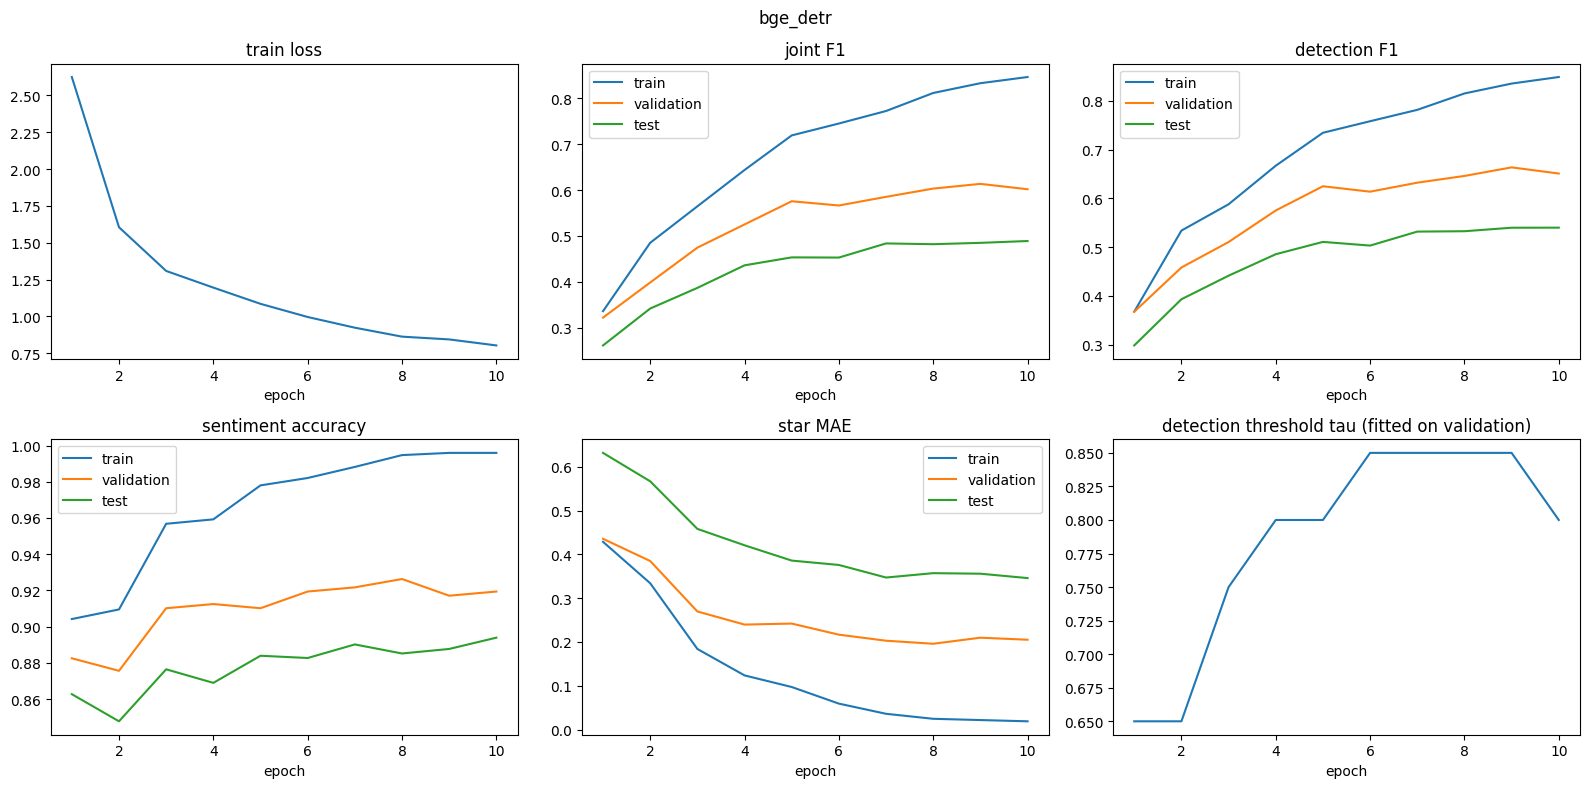


##############################################################################################################
# lfm_base
##############################################################################################################
RUN lfm_base  device cuda (bfloat16)  encoder LiquidAI/LFM2.5-Encoder-230M 229,693,184 parameters + head 492,000
settings: drop_blocks (), conv_kernel 3, layer_mix False, supcon 0.0, head linear, factorised False, gate False, loss bce, context False, neg_scope False, long_aug 0.0, llrd 1.0, encoder lr 3e-05, head lr 0.001, batch 32, epochs 10, max_len 56, seed 2026
data: train 2109 sentences (+0 long inputs per epoch), validation 366, test 808; 80 categories; 66 steps per epoch


ARCHITECTURE  ABSAClassifier  on  LiquidAI/LFM2.5-Encoder-230M
LiquidAI/LFM2.5-Encoder-230M: hidden 1024, vocab 65536, 14 blocks, 16 query / 8 kv heads, conv kernel 3, feed-forward 2560, RoPE theta 1e+06
  embed_tokens              67,108,864
  block  0  conv            12,063,744

,sentiment,gold,pred,tp,P,R,F1
0,negative,274,154,72,0.468,0.263,0.336
1,neutral,46,8,2,0.250,0.043,0.074
2,positive,481,417,244,0.585,0.507,0.543



-- sentiment_confusion


,pred_negative,pred_neutral,pred_positive
gold_negative,231,7,28
gold_neutral,18,5,22
gold_positive,33,7,437



-- star_confusion


,pred_0,pred_1,pred_2,pred_3,pred_4
gold_0,167,64,7,16,12
gold_1,0,0,0,0,0
gold_2,11,7,5,16,6
gold_3,0,0,0,0,0
gold_4,11,22,7,58,379



-- confidence_coverage


,min_conf,coverage,sentiment_acc
0,0.0,1.000,0.854
1,0.5,0.981,0.867
2,0.6,0.951,0.881
3,0.7,0.920,0.892
4,0.8,0.887,0.901
5,0.9,0.826,0.916



-- by_entity (test)


,label,gold,pred,tp_joint,joint_P,joint_R,joint_F1,det_P,det_R,det_F1
0,LAPTOP,472,406,241,0.594,0.511,0.549,0.648,0.557,0.599
4,DISPLAY,50,26,12,0.462,0.240,0.316,0.500,0.260,0.342
1,COMPANY,38,8,5,0.625,0.132,0.217,0.625,0.132,0.217
9,SUPPORT,35,30,14,0.467,0.400,0.431,0.500,0.429,0.462
10,OS,34,13,4,0.308,0.118,0.170,0.385,0.147,0.213
12,KEYBOARD,31,17,6,0.353,0.194,0.250,0.353,0.200,0.255
11,MOUSE,26,23,7,0.304,0.269,0.286,0.348,0.308,0.327
2,BATTERY,25,21,14,0.667,0.560,0.609,0.714,0.600,0.652
3,HARD_DISC,21,10,5,0.500,0.238,0.323,0.600,0.286,0.387
6,MULTIMEDIA_DEVICES,17,10,5,0.500,0.294,0.370,0.500,0.312,0.385


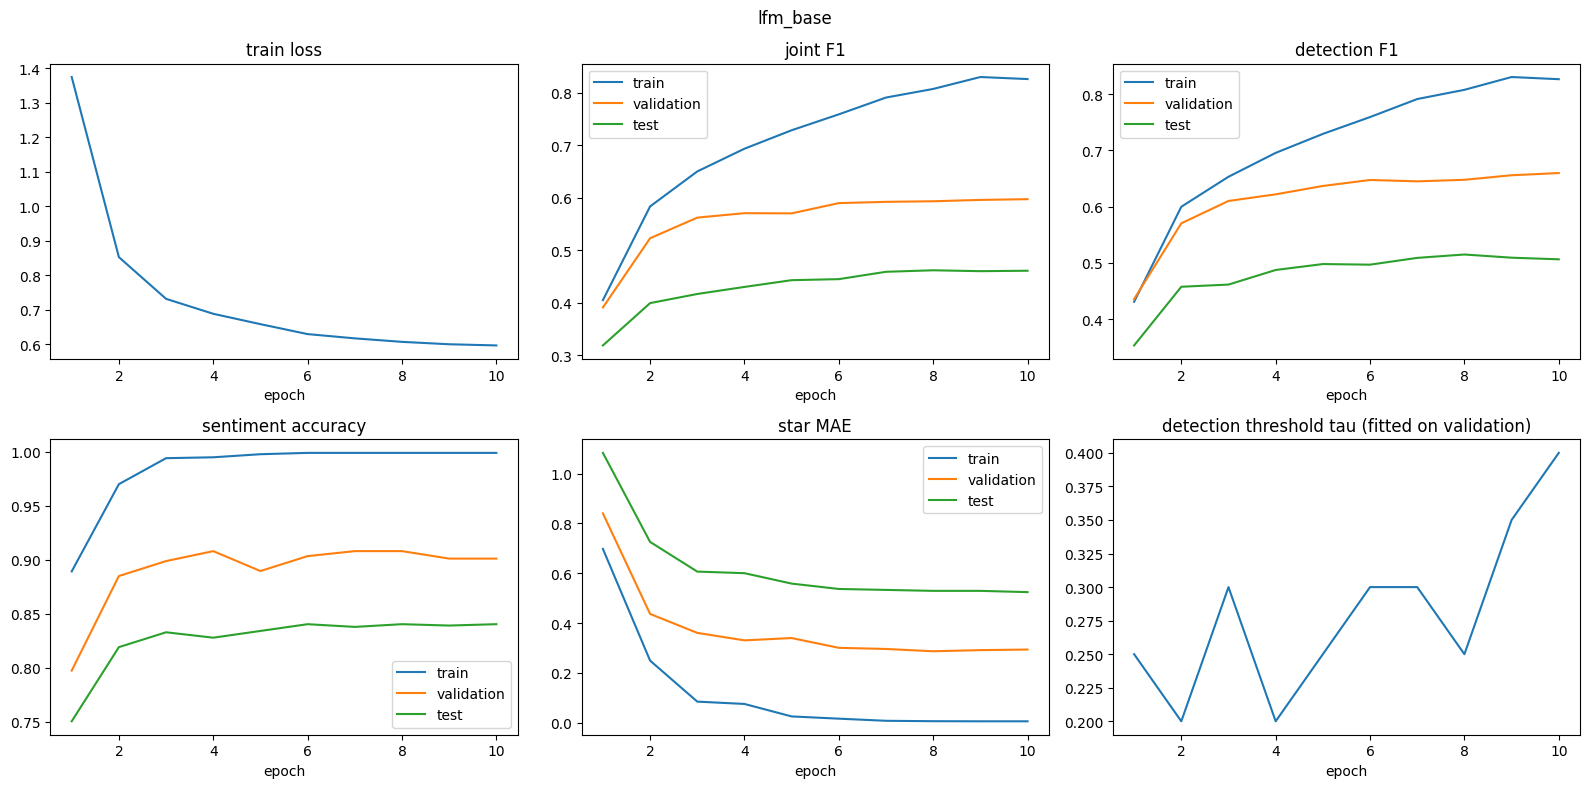


##############################################################################################################
# lfm_tweaked
##############################################################################################################
RUN lfm_tweaked  device cuda (bfloat16)  encoder LiquidAI/LFM2.5-Encoder-230M 229,696,256 parameters + head 460,406
settings: drop_blocks (), conv_kernel 3, layer_mix False, supcon 0.0, head catattn, factorised True, gate True, loss asl, context True, neg_scope True, long_aug 0.25, llrd 0.9, encoder lr 3e-05, head lr 0.001, batch 32, epochs 10, max_len 56, seed 2026
data: train 2109 sentences (+527 long inputs per epoch), validation 366, test 808; 80 categories; 83 steps per epoch


ARCHITECTURE  ABSAClassifier  on  LiquidAI/LFM2.5-Encoder-230M
LiquidAI/LFM2.5-Encoder-230M: hidden 1024, vocab 65536, 14 blocks, 16 query / 8 kv heads, conv kernel 3, feed-forward 2560, RoPE theta 1e+06
  embed_tokens              67,108,864
  block  0  conv            12,0

Traceback (most recent call last):
  File "/tmp/ipykernel_1042/263471240.py", line 6, in <cell line: 0>
    RESULTS[name] = run_experiment(name)
                    ~~~~~~~~~~~~~~^^^^^^
  File "/tmp/ipykernel_1042/549756293.py", line 109, in run_experiment
    loss, parts = model.loss(model(batch), batch)
                             ~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1779, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1790, in _call_impl
    return forward_call(*args, **kwargs)
  File "/tmp/ipykernel_1042/1449530043.py", line 90, in forward
    v = self.drop(torch.einsum("wct,wth->wch", attn, states))
                  ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/functional.py", line 373, in einsum
    return _VF.einsum(equation, o

RUN lfm_detr  device cuda (bfloat16)  encoder LiquidAI/LFM2.5-Encoder-230M 229,696,256 parameters + head 2,383,909
settings: drop_blocks (), conv_kernel 3, layer_mix False, supcon 0.0, head set, factorised False, gate False, loss bce, context True, neg_scope True, long_aug 0.25, llrd 0.9, encoder lr 3e-05, head lr 0.001, batch 32, epochs 10, max_len 56, seed 2026
data: train 2109 sentences (+527 long inputs per epoch), validation 366, test 808; 198 categories; 83 steps per epoch


ARCHITECTURE  ABSASetDetector  on  LiquidAI/LFM2.5-Encoder-230M
LiquidAI/LFM2.5-Encoder-230M: hidden 1024, vocab 65536, 14 blocks, 16 query / 8 kv heads, conv kernel 3, feed-forward 2560, RoPE theta 1e+06
  embed_tokens              67,108,864
  block  0  conv            12,063,744   (operator 4,197,376, feed-forward 7,864,320)
  block  1  conv            12,063,744   (operator 4,197,376, feed-forward 7,864,320)
  block  2  attention       11,012,224   (operator 3,145,856, feed-forward 7,864,320)
  block  3  

Traceback (most recent call last):
  File "/tmp/ipykernel_1042/263471240.py", line 6, in <cell line: 0>
    RESULTS[name] = run_experiment(name)
                    ~~~~~~~~~~~~~~^^^^^^
  File "/tmp/ipykernel_1042/549756293.py", line 109, in run_experiment
    loss, parts = model.loss(model(batch), batch)
                             ~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1779, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1790, in _call_impl
    return forward_call(*args, **kwargs)
  File "/tmp/ipykernel_1042/1965349753.py", line 57, in forward
    mem = self.memory(encode(self.encoder, batch))  # [W, T, d]
                      ~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_1042/1449530043.py", line 7, in encode
    return encoder(ids, mask, types)
  File "/usr/local/lib/python3.13

In [18]:
# RUN-EXPERIMENTS-CELL
RESULTS, FAILED = {}, {}
for name in CFG.runs:
    print("\n" + "#" * 110 + f"\n# {name}\n" + "#" * 110)
    try:
        RESULTS[name] = run_experiment(name)
    except Exception as e:
        FAILED[name] = f"{type(e).__name__}: {e}"
        print(f"\n!!! {name} FAILED: {FAILED[name]}"); traceback.print_exc()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
print("\nfinished:", [n for n, r in RESULTS.items() if not r.get("skipped")], "| skipped:", [n for n, r in RESULTS.items() if r.get("skipped")],
      "| failed:", FAILED or "none")

## 14. Compare runs

For every run: the epoch with the best validation joint F1 and the last epoch, test metrics (the test CSV when there is one, otherwise the held-out test split). Saved as `summary.csv` and `summary_extended.csv`.

TEST SET, %; star MAE in stars
run          epoch          val joint F1  det P  det R  det F1  ent F1  attr F1  sent acc  sent mF1  joint P  joint R  joint F1  empty acc  star MAE  cover90  conf
-----------  -------------  ------------  -----  -----  ------  ------  -------  --------  --------  -------  -------  --------  ---------  --------  -------  ----
bge_base     9 (best val)           46.1   43.6   40.8    42.1    56.4     53.8      82.8      65.8     37.3     34.8      36.0       52.3      0.53     91.6  91.4
bge_base     10 (last)              45.6   43.2   40.9    42.1    56.0     53.9      82.7      65.6     37.0     35.0      36.0       51.1      0.53     91.8  91.3
bge_detr     9 (best val)           61.4   50.4   55.2    52.7    63.9     61.3      88.6      71.2     45.7     49.9      47.7       43.0      0.35     93.8  93.9
bge_detr     10 (last)              60.2   51.2   55.3    53.2    63.9     61.8      88.4      71.3     46.2     49.8      48.0       44.7      0.36 

run,bge_base,bge_detr,bge_tweaked,lfm_base
best_epoch,9.0000,9.0000,9.0000,10.0000
tau,0.2000,0.8500,0.6000,0.4000
val_joint_f1,0.4614,0.6135,0.4499,0.5971
joint_f1_negative,0.2462,0.3971,0.2810,0.3364
joint_f1_neutral,0.0759,0.1395,0.0909,0.0741
joint_f1_positive,0.4350,0.5628,0.4397,0.5434
joint_macro_f1_sentiment,0.2524,0.3665,0.2705,0.3180
detect_AP_micro,0.3862,0.5319,0.3502,0.5330
detect_AUC_micro,0.9316,0.9844,0.8948,0.9618
detect_mAP_macro,0.2151,0.3872,0.2219,0.3312


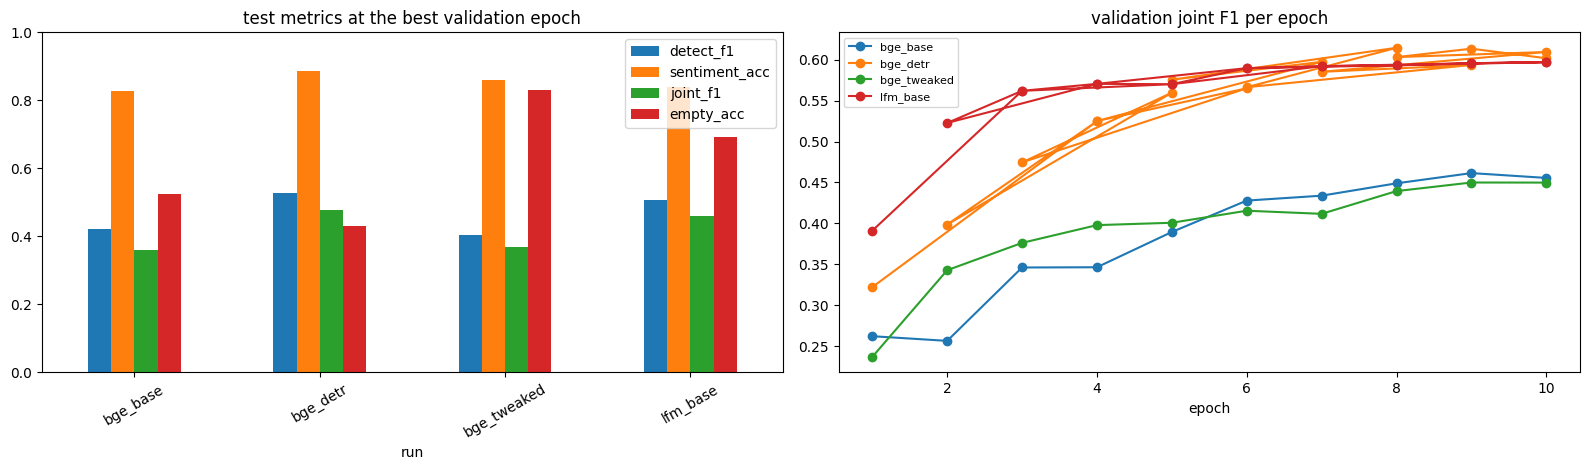

In [19]:
def tabulate(out: Path = OUT) -> pd.DataFrame | None:
    """Every run in `out`: the epoch with the best validation joint F1 and the last epoch, test metrics."""
    rows, keep = [], []
    for path in sorted(out.glob("*/metrics.csv")):
        with path.open(encoding="utf-8") as f:
            data = list(csv.DictReader(f))
        val = {int(r["epoch"]): float(r["joint_f1"]) for r in data if r["split"] == "validation"}
        if not val:
            continue
        best, last = max(val, key=val.get), max(val)
        for tag, ep in (("best val", best), ("last", last)):
            t = next(r for r in data if r["split"] == "test" and int(r["epoch"]) == ep)
            rows.append([path.parent.name, f"{ep} ({tag})", f"{100 * val[ep]:.1f}",
                         *(f"{float(t[k]):.2f}" if k == "star_mae" else f"{100 * float(t[k]):.1f}" for k, _ in COLUMNS)])
            keep.append({"run": path.parent.name, "epoch": ep, "which": tag, "val_joint_f1": val[ep], **{k: float(t[k]) for k, _ in COLUMNS}})
    if not rows:
        print(f"no runs in {out}/: run the experiments first"); return None
    print("TEST SET, %; star MAE in stars")
    print("\n".join(table(["run", "epoch", "val joint F1", *(h for _, h in COLUMNS)], rows)))
    df = pd.DataFrame(keep); df.to_csv(out / "summary.csv", index=False)
    print(f"saved {short(out / 'summary.csv')}")
    return df


def tabulate_extended(out: Path = OUT) -> pd.DataFrame | None:
    rows = []
    for rep in sorted(out.glob("*/best_epoch_report/scalars_test.json")):
        run = rep.parent.parent
        info = dict(l.split(" ", 1) for l in (rep.parent / "best_epoch.txt").read_text().splitlines())
        S = json.loads(rep.read_text())
        rows.append({"run": run.name, "best_epoch": int(info["epoch"]), "tau": float(info["tau"]), "val_joint_f1": float(info["val"].split()[-1]) if info.get("val") else np.nan, **S})
    if not rows: return None
    df = pd.DataFrame(rows); df.to_csv(out / "summary_extended.csv", index=False)
    return df


summary = tabulate()
ext_summary = tabulate_extended()
if ext_summary is not None:
    print("\nEXTENDED METRICS at each run's best-validation epoch (test set)")
    display(ext_summary.set_index("run").round(4).T)

if summary is not None:
    best_rows = summary[summary.which == "best val"].set_index("run")
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
    best_rows[["detect_f1", "sentiment_acc", "joint_f1", "empty_acc"]].plot.bar(ax=ax[0], rot=30)
    ax[0].set_title("test metrics at the best validation epoch"); ax[0].set_ylim(0, 1)
    for path in sorted(OUT.glob("*/metrics.csv")):
        d = pd.read_csv(path); d = d[d.split == "validation"]
        ax[1].plot(d.epoch, d.joint_f1, marker="o", label=path.parent.name)
    ax[1].set_title("validation joint F1 per epoch"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(OUT / "compare_runs.png", dpi=110); plt.show()

## 15. Inference with a saved checkpoint

`load_checkpoint(folder)` needs only the checkpoint folder (no download, no training data). `analyse(review_text, ...)` splits text of any length into sentences (`split_sentences`), reads each sentence with its neighbours as review context, and scores a sentence longer than one window window by window. Each opinion: category (E#A), star 0-4, 90% star interval, final sentiment from the star brackets and the interval, its confidence, and the detection score.

In [20]:
def load_checkpoint(folder, device="cpu"):
    """A checkpoint folder -> (model, inputs, config). Needs only the folder: no download, no training data."""
    folder = Path(folder)
    cfg = json.loads((folder / "config.json").read_text(encoding="utf-8"))
    v = cfg["settings"]
    label_space_from_categories(cfg["categories"])   # the set detector needs its entity / attribute lists
    encoder = BASES[cfg["model"]].from_config(folder)
    model = build(cfg["model"], v, cfg["categories"], encoder, wrap=cfg["wrapped"])
    model.load_state_dict(torch.load(folder / "model.pt", map_location="cpu", weights_only=True))
    inputs = make_inputs(cfg["model"], v, str(folder / "tokenizer.json"))
    return model.to(device).eval(), inputs, cfg


def analyse(review: str, model, inputs, cfg: dict, device) -> list[dict]:
    """Review text -> one record per sentence with its opinions."""
    sents = split_sentences(review)
    if not sents:
        return []
    examples = [Example(f"s:{k}", "input", t, sents[k - 1] if k else "", sents[k + 1] if k + 1 < len(sents) else "")
                for k, t in enumerate(sents)]
    det, pol = predict(model, inputs, examples, device)
    s = star_summary(pol)
    out = []
    for i, ex in enumerate(examples):
        ops = [describe_opinion(model.categories[j], s, i, j, float(det[i, j])) for j in np.flatnonzero(det[i] >= cfg["tau"])]
        out.append({"sentence": ex.text, "opinions": sorted(ops, key=lambda o: -o["score"])})
    return out


def show(records: list[dict]) -> None:
    for r in records:
        tuples = ", ".join(f"{{{o['category']}, {o['sentiment']}}}" for o in r["opinions"]) or "(no opinion)"
        print(f"{r['sentence']}\n  -> {tuples}")
        for o in r["opinions"]:
            lo, hi = o["star_interval_90"]
            print(f"     {o['category']:<36} star {o['star']} (expected {o['expected_star']:.2f}, 90% interval {lo}-{hi})  "
                  f"{o['sentiment']} {100 * o['confidence']:.0f}%{'' if o['certain'] else ' (uncertain)'}  "
                  f"detection {o['score']:.2f}")
    print(json.dumps(records, ensure_ascii=False))


def evaluate_checkpoint(folder, device="cpu", test=None) -> dict:
    """Score a checkpoint on the test set with the threshold stored in it (fitted on validation)."""
    model, inputs, cfg = load_checkpoint(folder, device)
    test = test or TEST
    det, pol = predict(model, inputs, test, device)
    m = Scorer(test, model.categories).score(det, pol, cfg["tau"])
    print(f"{folder}: {cfg['model']}_{cfg['variant']} epoch {cfg['epoch']}, threshold {cfg['tau']:.2f} (from validation)")
    print("\n".join(table(METRIC_HEAD, metric_rows({"test": m}))))
    return m


def best_checkpoint(out: Path = OUT):
    """(run folder, epoch folder) of the run + epoch with the best validation joint F1 among runs whose weights are on disk."""
    best = None
    for path in sorted(out.glob("*/metrics.csv")):
        d = pd.read_csv(path); d = d[d.split == "validation"]
        for _, r in d.iterrows():
            ck = path.parent / f"checkpoint_{int(r.epoch)}"
            if (ck / "model.pt").exists() and (best is None or r.joint_f1 > best[0]): best = (r.joint_f1, ck)
    return best[1] if best else None


ck = best_checkpoint()
if ck is None:
    print("no checkpoint with weights found: run the experiments first")
else:
    dev = pick_device("auto")
    print("best checkpoint:", short(ck))
    m, inp, c = load_checkpoint(ck, dev)
    for t in ["Great screen, but the battery dies fast.", "The keyboard is not bad. Shipping took forever though! I love the price."]:
        show(analyse(t, m, inp, c, dev))
    evaluate_checkpoint(ck, dev)

best checkpoint: result/bge_detr/checkpoint_8
Great screen, but the battery dies fast.
  -> {BATTERY#OPERATION_PERFORMANCE, negative}, {DISPLAY#QUALITY, positive}, {DISPLAY#GENERAL, positive}
     BATTERY#OPERATION_PERFORMANCE        star 0 (expected 0.20, 90% interval 0-1)  negative 100%  detection 0.98
     DISPLAY#QUALITY                      star 3 (expected 3.18, 90% interval 0-4)  positive 83% (uncertain)  detection 0.97
     DISPLAY#GENERAL                      star 4 (expected 3.74, 90% interval 3-4)  positive 100%  detection 0.88
[{"sentence": "Great screen, but the battery dies fast.", "opinions": [{"category": "BATTERY#OPERATION_PERFORMANCE", "sentiment": "negative", "star": 0, "expected_star": 0.2, "star_interval_90": [0, 1], "confidence": 0.997, "certain": true, "score": 0.985}, {"category": "DISPLAY#QUALITY", "sentiment": "positive", "star": 3, "expected_star": 3.18, "star_interval_90": [0, 4], "confidence": 0.834, "certain": false, "score": 0.968}, {"category": "DISPLAY#

## 16. Package the results

The zip contains every metric / log / report / plot / prediction file and the `model.pt` of each run's best epoch only (all epochs would be gigabytes). To keep every epoch's weights, copy `result/` from Colab or set `CFG.save_to_drive=True`.

In [21]:
import zipfile
zip_path = Path("absa_experiments.zip")
best_ck = {}
for rep in OUT.glob("*/best_epoch_report/best_epoch.txt"):
    best_ck[rep.parent.parent.name] = int(rep.read_text().split()[1])
n_files = 0
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob("*")):
        if not p.is_file(): continue
        if p.name == "model.pt":
            run, ck = p.parent.parent.name, p.parent.name
            if best_ck.get(run) != int(ck.split("_")[1]): continue
        z.write(p, p.relative_to(OUT.parent)); n_files += 1
print(f"{zip_path}: {n_files} files, {zip_path.stat().st_size / 1e6:.0f} MB")
for p in sorted(OUT.iterdir()): print("  ", p.name)
try:
    from google.colab import files; files.download(str(zip_path))
except ImportError:
    pass

absa_experiments.zip: 364 files, 1220 MB
   bge_base
   bge_detr
   bge_tweaked
   compare_runs.png
   data_report.txt
   lfm_base
   lfm_detr
   lfm_tweaked
   summary.csv
   summary_extended.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>